# Text Mining of Hotel Customer Reviews

**Project:** Integrated Hotel Analytics for Hotel Success, Amenities & Customer Experience
**Team 5**

**Individual Contributor:** Durgam Poojitha — CB.SC.U4CSE23320

**Review 2 · Method 1 (Text Mining)** — preprocessing, word frequency, word cloud, sentiment/pattern analysis and evaluation

> Every number, table and chart in this notebook is calculated from the uploaded CSV (`all_india_hotel_cleaned`). Interpretation text that quotes numbers is generated by code from those results, so nothing is hard-coded.

## Section 1 — Objective

**Why review text matters.** Star ratings and hotel attributes tell us *how well* a hotel is rated, but not *why*. A guest who gives 3 stars may be unhappy with Wi-Fi, noise or service, and the number alone does not say which. Review text is the only place where customers describe their experience in their own words.

**Why Review 1 was not sufficient.** Review 1 worked at *hotel level* (one row per hotel). It used price, review count, amenity count and amenity flags to predict a rating-based success label (rating ≥ 4.0). That shows which *characteristics are associated with success*, but it ignores what customers actually wrote. Review 1 itself lists customer-review analysis as scope for further work.

**Why text mining is added in Review 2.** Text mining works at *review level* and turns free text into measurable evidence: frequent words and phrases, sentiment, positive/negative patterns, pain points, and sentiment around amenities.

**How it complements the other methods.**
- Classification / EDA (Review 1): hotel characteristics → hotel success
- Text mining (this notebook): customer reviews → sentiment and pain points
- Association rules (teammate): which amenities occur together
- Together they feed the integrated business recommendations.

| Review | Question answered |
|---|---|
| **Review 1** | *What characteristics are associated with hotel success?* |
| **Review 2 – Text Mining** | *What are customers actually saying about their experience?* |

**Questions this notebook answers:** frequent words → main topics → positive/neutral/negative split → positive vs negative themes → pain points → amenity sentiment → agreement between text sentiment and ratings → business actions.

## Section 2 — Load Data

In [1]:
# ---- Imports (installs missing packages safely; works in Google Colab and Jupyter) ----
import warnings, re, os, sys, glob, json, subprocess, zipfile, html
warnings.filterwarnings("ignore")

def _ensure(module, pip_name=None):
    try:
        __import__(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])

_ensure("nltk"); _ensure("wordcloud")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, cohen_kappa_score, roc_auc_score)
from IPython.display import display, Markdown

# NLTK resources (safe to re-run)
for res in ["stopwords", "wordnet", "omw-1.4", "vader_lexicon"]:
    nltk.download(res, quiet=True)

# ---- Plot style ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
SENT_ORDER  = ["Negative", "Neutral", "Positive"]
SENT_COLORS = {"Negative": "#c0392b", "Neutral": "#95a5a6", "Positive": "#2e8b57"}

OUT_DIR = "text_mining_outputs"          # charts + CSVs for the dashboard / presentation team
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
print("Libraries ready. Outputs will be saved to:", os.path.abspath(OUT_DIR))

Libraries ready. Outputs will be saved to: /home/claude/run/text_mining_outputs


In [2]:
# ---- Locate and load the CSV (handles "all_india_hotel_cleaned.csv" and "all_india_hotel_cleaned(4).csv") ----
search_dirs = [".", "/content", "/content/drive/MyDrive", "/mnt/user-data/uploads"]
found = []
for d in search_dirs:
    found += glob.glob(os.path.join(d, "all_india_hotel_cleaned*.csv"))

if not found:
    try:                                   # Google Colab upload prompt
        from google.colab import files
        up = files.upload()
        found = [k for k in up if k.endswith(".csv")]
    except ImportError:
        raise FileNotFoundError("Place all_india_hotel_cleaned.csv next to this notebook and re-run.")

CSV_PATH = found[0]
df = None
for enc in ["utf-8", "utf-8-sig", "latin-1"]:          # graceful encoding fallback
    try:
        df = pd.read_csv(CSV_PATH, encoding=enc)
        print(f"Loaded '{CSV_PATH}' with encoding = {enc}")
        break
    except UnicodeDecodeError:
        print(f"Encoding {enc} failed, trying next...")

N_COLS_ORIG = df.shape[1]                      # remember the original column count (we add helper columns later)
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
display(df.dtypes.rename("dtype").to_frame().T.T)
display(df.head())

Loaded './all_india_hotel_cleaned.csv' with encoding = utf-8
Shape: (29987, 42)

Columns: ['hotel_name', 'hotel_id', 'state', 'location', 'price_per_night', 'hotel_category', 'customer_rating', 'review_count', 'amenities', 'review_text', 'individual_review_rating', 'review_date', 'review_source', 'search_area', 'latitude', 'longitude', 'review_id', 'source_file', 'city', 'location_raw', 'review_source_raw', 'price_raw', 'rating_raw', 'review_text_raw', 'amenities_raw', 'review_source_clean', 'rating_scale', 'rating_norm', 'analysis_location', 'location_basis', 'price', 'price_outlier_flag', 'log_price', 'hotel_category_clean', 'amenity_count', 'review_text_clean', 'review_text_missing', 'review_count_clean', 'customer_rating_clean', 'latitude_clean', 'longitude_clean', 'review_date_clean']


,dtype
hotel_name,str
hotel_id,str
state,str
location,str
price_per_night,str
hotel_category,str
customer_rating,float64
review_count,float64
amenities,str
review_text,str


,hotel_name,hotel_id,state,location,price_per_night,hotel_category,customer_rating,review_count,amenities,review_text,...,log_price,hotel_category_clean,amenity_count,review_text_clean,review_text_missing,review_count_clean,customer_rating_clean,latitude_clean,longitude_clean,review_date_clean
0,FabHotel Gita Residency,ChkIiPjvnbTqrrE9Gg0vZy8xMW1zNm12Y2pyEAE,Andhra Pradesh,Andhra Pradesh,"₹1,256",NaN,5.0,22.0,Free Wi-Fi | Free parking | Air conditioning | Pet-friendly | Room service | Full-service laundry | Access...,Rooms are very spacious and cleaning is good,...,7.136483,Unknown,7,Rooms are very spacious and cleaning is good,False,22.0,5.0,17.682735,83.205808,a month ago
1,FabHotel Gita Residency,ChkIiPjvnbTqrrE9Gg0vZy8xMW1zNm12Y2pyEAE,Andhra Pradesh,Andhra Pradesh,"₹1,256",NaN,5.0,22.0,Free Wi-Fi | Free parking | Air conditioning | Pet-friendly | Room service | Full-service laundry | Access...,Good rooms,...,7.136483,Unknown,7,Good rooms,False,22.0,5.0,17.682735,83.205808,a month ago
2,FabHotel Gita Residency,ChkIiPjvnbTqrrE9Gg0vZy8xMW1zNm12Y2pyEAE,Andhra Pradesh,Andhra Pradesh,"₹1,256",NaN,5.0,22.0,Free Wi-Fi | Free parking | Air conditioning | Pet-friendly | Room service | Full-service laundry | Access...,Good staff well mannered maintenance very good,...,7.136483,Unknown,7,Good staff well mannered maintenance very good,False,22.0,5.0,17.682735,83.205808,a month ago
3,FabHotel Gita Residency,ChkIiPjvnbTqrrE9Gg0vZy8xMW1zNm12Y2pyEAE,Andhra Pradesh,Andhra Pradesh,"₹1,256",NaN,5.0,22.0,Free Wi-Fi | Free parking | Air conditioning | Pet-friendly | Room service | Full-service laundry | Access...,Clean and well mannered staff,...,7.136483,Unknown,7,Clean and well mannered staff,False,22.0,5.0,17.682735,83.205808,a month ago
4,FabHotel Gita Residency,ChkIiPjvnbTqrrE9Gg0vZy8xMW1zNm12Y2pyEAE,Andhra Pradesh,Andhra Pradesh,"₹1,256",NaN,5.0,22.0,Free Wi-Fi | Free parking | Air conditioning | Pet-friendly | Room service | Full-service laundry | Access...,Good cleaning,...,7.136483,Unknown,7,Good cleaning,False,22.0,5.0,17.682735,83.205808,a month ago


## Section 3 — Dataset Profiling

We first confirm what is really in the file before analysing anything. Columns are detected by name so the notebook still runs if a name differs slightly.

In [3]:
# ---- Automatic column detection (falls back to alternatives if a name is missing) ----
def pick(*names):
    for n in names:
        if n in df.columns:
            return n
    return None

COL = dict(
    text_raw   = pick("review_text_raw", "review_text"),
    text_clean = pick("review_text_clean", "review_text"),
    rating_raw = pick("individual_review_rating"),
    rating_norm= pick("rating_norm"),
    rating_scale=pick("rating_scale"),
    hotel_id   = pick("hotel_id"),
    hotel_name = pick("hotel_name"),
    category   = pick("hotel_category_clean", "hotel_category"),
    amenities  = pick("amenities", "amenities_raw"),
    amen_count = pick("amenity_count"),
    city       = pick("analysis_location", "city", "location"),
    source     = pick("review_source_clean", "review_source"),
    review_id  = pick("review_id"),
)
print("Detected columns:"); [print(f"  {k:12s} -> {v}") for k, v in COL.items()]

# Verify the columns we plan to rely on actually exist
expected = ["hotel_name","hotel_id","state","location","price_per_night","hotel_category","customer_rating","review_count",
            "amenities","review_text","individual_review_rating","review_date","review_source","search_area","latitude","longitude",
            "review_id","source_file","city","review_text_raw","amenities_raw","review_source_clean","rating_scale","rating_norm",
            "analysis_location","amenity_count","review_text_clean","review_text_missing","hotel_category_clean"]
print("\nExpected columns missing from the CSV:", [c for c in expected if c not in df.columns] or "none")

Detected columns:
  text_raw     -> review_text_raw
  text_clean   -> review_text_clean
  rating_raw   -> individual_review_rating
  rating_norm  -> rating_norm
  rating_scale -> rating_scale
  hotel_id     -> hotel_id
  hotel_name   -> hotel_name
  category     -> hotel_category_clean
  amenities    -> amenities
  amen_count   -> amenity_count
  city         -> analysis_location
  source       -> review_source_clean
  review_id    -> review_id

Expected columns missing from the CSV: none


In [4]:
# ---- Profiling ----
has_text      = df[COL["text_clean"]].notna() & df[COL["text_clean"]].astype(str).str.strip().ne("")
words_raw     = df.loc[has_text, COL["text_clean"]].astype(str).str.split().str.len()
chars_raw     = df.loc[has_text, COL["text_clean"]].astype(str).str.len()

profile = pd.DataFrame({"Metric": [
    "Total records (rows)", "Total columns", "Reviews available (non-empty text)", "Missing review text",
    "Unique review texts", "Unique hotels (all rows)", "Hotels with usable review text",
    "Missing individual review rating", "Exact duplicate rows", "Average review length (words)",
    "Median review length (words)"],
  "Value": [
    f"{len(df):,}", N_COLS_ORIG, f"{has_text.sum():,}", f"{(~has_text).sum():,} ({(~has_text).mean()*100:.1f}%)",
    f"{df.loc[has_text, COL['text_clean']].nunique():,}", f"{df[COL['hotel_id']].nunique():,}",
    f"{df.loc[has_text, COL['hotel_id']].nunique():,}", f"{df[COL['rating_raw']].isna().sum():,}",
    f"{df.duplicated().sum():,}", f"{words_raw.mean():.1f}", f"{words_raw.median():.0f}"]})
display(profile)

print("Missing values (only columns with gaps):")
miss = df.isna().sum(); display(miss[miss > 0].sort_values(ascending=False).to_frame("missing").assign(pct=lambda x: (x.missing/len(df)*100).round(1)))

print("Rating distribution (individual_review_rating):")
display(df[COL["rating_raw"]].value_counts().sort_index().to_frame("reviews").T)
print("Descriptive statistics of numeric columns:")
display(df[[COL["rating_raw"], "customer_rating", "amenity_count"]].describe().round(2))
print("Random sample of 5 rows (text columns):")
display(df.loc[has_text, [COL["hotel_name"], COL["category"], COL["rating_raw"], COL["text_clean"]]].sample(5, random_state=42))

,Metric,Value
0,Total records (rows),"29,987"
1,Total columns,42
2,Reviews available (non-empty text),"26,281"
3,Missing review text,"3,706 (12.4%)"
4,Unique review texts,"23,557"
5,Unique hotels (all rows),"1,685"
6,Hotels with usable review text,"1,659"
7,Missing individual review rating,23
8,Exact duplicate rows,0
9,Average review length (words),33.4


Missing values (only columns with gaps):


,missing,pct
state,24291,81.0
review_id,20767,69.3
latitude,20744,69.2
longitude,20744,69.2
latitude_clean,20744,69.2
longitude_clean,20744,69.2
hotel_category,9911,33.1
amenities,4138,13.8
amenities_raw,4138,13.8
review_text_raw,3706,12.4


Rating distribution (individual_review_rating):


individual_review_rating,0.5,1.0,1.2,1.5,1.7,2.0,2.2,2.5,2.8,3.0,...,7.0,7.1,7.5,8.0,8.3,8.8,9.0,9.2,9.6,10.0
reviews,2,4963,2,2,1,978,1,2,2,1551,...,13,1,6,45,2,4,62,2,8,247


Descriptive statistics of numeric columns:


,individual_review_rating,customer_rating,amenity_count
count,29964.00,29959.00,29987.00
mean,4.08,4.16,8.11
std,1.64,0.47,4.36
min,0.50,1.00,0.00
25%,3.00,3.90,6.00
50%,5.00,4.20,9.00
75%,5.00,4.50,11.00
max,10.00,5.00,18.00


Random sample of 5 rows (text columns):


,hotel_name,hotel_category_clean,individual_review_rating,review_text_clean
23747,"Maliekal Heritance - Resort In Cherai, Luxury Resort in Cherai, Kochi",5-star hotel,5.0,"Really enjoyed the overall experience. Kayaking and water cycling were fun activities, and the property it..."
8359,Ramada Plaza by Wyndham Chennai,5-star hotel,4.0,Went for the rooftop restaurant. Great view. Very good ambience for a quick meeting. Food cost is on the h...
10266,FabExpress B Zone,3-star hotel,4.0,No restaurant. For food we need to go out. People are not friendly. No support staff. Front office was not...
19224,Hotel Eminent Suites,1-star hotel,5.0,"Wonderful stay in Hyderabad! The staff were warm, friendly, and very cooperative, with everything well pla..."
7577,Le Royal Méridien Chennai,5-star hotel,4.0,We stayed there for three hours to attend a wedding on 19.9.26. We booked for one day but stayed only thre...


**Reading the profile.** The file holds one row per *review* (hotel details repeat on every row). Only rows with non-empty text can be text-mined; rows with ratings but no text are kept out of the text corpus. We use the **review-level** data throughout — we do **not** collapse reviews to one row per hotel, because the aim is to analyse what individual customers say.

## Section 4 — Select Text Data

Review 1 produced `review_text_clean`. Before reusing it we check whether it is *genuinely* cleaned, by comparing the three text columns on real reviews.

In [5]:
t_raw, t_cln = COL["text_raw"], COL["text_clean"]
tmp = df[has_text].copy()

# 1) Does the "clean" column differ from the raw one only in whitespace?
ws_only = (tmp[t_raw].astype(str).str.split().str.join(" ") == tmp[t_cln].astype(str))
print(f"review_text_clean equals review_text_raw after collapsing whitespace: {ws_only.mean()*100:.1f}% of reviews")

# 2) What 'dirt' is still inside review_text_clean?
s = tmp[t_cln].astype(str)
issues = {
  "Contains '(Translated by Google) ... (Original) ...' block": s.str.contains(r"\(Translated by Google\)", regex=True).sum(),
  "Contains non-ASCII characters (emoji / other scripts)":      s.str.contains(r"[^\x00-\x7F]", regex=True).sum(),
  "Contains Indic-script text":                                  s.str.contains(r"[\u0900-\u0D7F]", regex=True).sum(),
  "Contains '|' separators between sub-reviews":                 s.str.contains(r"\|", regex=True).sum(),
  "Contains upper-case letters":                                 s.str.contains(r"[A-Z]", regex=True).sum(),
  "Contains punctuation":                                        s.str.contains(r"[^\w\s]", regex=True).sum(),
}
display(pd.Series(issues, name="reviews affected").to_frame().assign(pct=lambda x: (x["reviews affected"]/len(tmp)*100).round(1)))

print("\nExamples where raw and clean differ:")
display(tmp.loc[tmp[t_raw].astype(str) != tmp[t_cln].astype(str), [t_raw, t_cln]].head(3))
print("Example of a translated review:")
display(tmp.loc[s.str.contains("Translated by Google"), [t_cln]].head(3))

review_text_clean equals review_text_raw after collapsing whitespace: 100.0% of reviews


,reviews affected,pct
Contains '(Translated by Google) ... (Original) ...' block,870,3.3
Contains non-ASCII characters (emoji / other scripts),4599,17.5
Contains Indic-script text,156,0.6
Contains '|' separators between sub-reviews,428,1.6
Contains upper-case letters,25849,98.4
Contains punctuation,18362,69.9



Examples where raw and clean differ:


,review_text_raw,review_text_clean
31,I booked a room through cleartrip and everything looks until i checkin the room.First thing AC is not cool...,I booked a room through cleartrip and everything looks until i checkin the room.First thing AC is not cool...
39,"Perfection means Maple! The Hospitality , the way they treat their customers to the end to end service jus...","Perfection means Maple! The Hospitality , the way they treat their customers to the end to end service jus..."
43,Everything about the property is great.\nReally very pocket friendly with top-notch facilities over the ma...,Everything about the property is great. Really very pocket friendly with top-notch facilities over the mai...


Example of a translated review:


,review_text_clean
105,(Translated by Google) Super sir (Original) సూపర్ సార్
106,(Translated by Google) 👍 Super (Original) 👍👍👍👍👍 సూపర్
234,(Translated by Google) Nice service 👍 (Original) Nice sarvice 👍


**Decision.** `review_text_clean` is only *whitespace-cleaned* (new-lines removed). It still contains translation artefacts, emoji, non-English scripts, punctuation and mixed case, so it is **not** ready for text mining. We therefore:

- keep the original columns untouched,
- reuse `review_text_clean` as the *starting point*, and
- build **two new columns**: `text_light` (light clean, used for VADER because VADER relies on punctuation, capitals and emoji) and `text_processed` (full NLP pipeline, used for word frequency, n-grams and word clouds).

For translated reviews (`(Translated by Google) <English> (Original) <foreign>`) we keep only the English translation and drop the foreign original.

## Section 5 — Text Preprocessing

Pipeline (each step is a separate, explainable function):

1. Handle missing reviews 2. Lowercase 3. Remove URLs 4. Remove HTML 5. Expand contractions (so *didn't* → *did not*, keeping the negation) 6. Remove punctuation and numbers 7. Normalise whitespace 8. Tokenise 9. Remove stop-words **except** `not, no, nor, never, neither` 10. Remove very short tokens 11. Lemmatise.

In [6]:
# ---------- Step A: artefact removal + light clean (used for VADER) ----------
TRANSLATED = re.compile(r"\(Translated by Google\)\s*(.*?)\s*\(Original\).*", flags=re.S)

def light_clean(text):
    """Keep punctuation, capitals and emoji (VADER uses them) but remove artefacts."""
    if pd.isna(text):                                   # 1. missing reviews
        return ""
    text = str(text)
    m = TRANSLATED.search(text)                         # keep English translation only
    if m:
        text = m.group(1)
    text = html.unescape(text)                          # &amp; -> &, &#128578; -> emoji
    text = re.sub(r"<[^>]+>", " ", text)                # 4. HTML tags
    text = re.sub(r"&?#\d{2,6};", " ", text)            # leftover numeric entities such as '#128578;'
    text = re.sub(r"(https?://\S+|www\.\S+)", " ", text)   # 3. URLs
    text = re.sub(r"\s*(\||\\n|\n)\s*", ". ", text)       # '|' and new-lines separate sentences
    text = re.sub(r"\s+", " ", text).strip()            # 7. whitespace
    text = re.sub(r"(\.\s*){2,}", ". ", text)          # collapse '. . .'
    return text

# ---------- Step B: full NLP pipeline (used for word frequency / n-grams) ----------
NEGATIONS  = {"not", "no", "nor", "never", "neither"}
STOP       = set(stopwords.words("english")) - NEGATIONS            # 10. keep negations
KEEP_SHORT = NEGATIONS | {"ac", "tv", "ok"}                          # short but meaningful tokens
tokenizer  = RegexpTokenizer(r"[a-z]+")                               # 8. tokenise letters only
lemmatizer = WordNetLemmatizer()

def expand_contractions(t):
    t = re.sub(r"\b(dont|doesnt|didnt|isnt|arent|wasnt|werent|hasnt|havent|hadnt|wouldnt|couldnt|shouldnt|cant|wont)\b", " not", t)  # no apostrophe
    t = re.sub(r"\bwon['’]t\b", "will not", t)
    t = re.sub(r"\bcan['’]t\b", "can not", t)
    t = re.sub(r"n['’]t\b", " not", t)                  # didn't -> did not, wasn't -> was not
    return t

def lemma(tok):
    return lemmatizer.lemmatize(lemmatizer.lemmatize(tok, "v"), "n")   # verbs first, then nouns

def to_tokens(text):
    t = text.lower()                                     # 2. lowercase
    t = expand_contractions(t)                           # 5. contractions
    t = re.sub(r"[^a-z\s]", " ", t)                      # 6. punctuation, numbers, emoji, other scripts
    toks = tokenizer.tokenize(t)                         # 8. tokens
    toks = [w for w in toks if w not in STOP]            # 9. stop-words (negations kept)
    toks = [lemma(w) for w in toks]                      # 11. lemmatise
    toks = [w for w in toks if w not in STOP]            #     (lemmas such as 'be'/'have' removed too)
    toks = [w for w in toks if len(w) >= 3 or w in KEEP_SHORT]   # 10. very short tokens
    return toks

demo = "The rooms were VERY clean!!! Great service."
print("Original :", demo); print("Light    :", light_clean(demo)); print("Processed:", " ".join(to_tokens(light_clean(demo))))

Original : The rooms were VERY clean!!! Great service.
Light    : The rooms were VERY clean!!! Great service.


Processed: room clean great service


In [7]:
# ---------- Apply to the whole file (originals are NOT overwritten) ----------
df["text_light"]     = df[COL["text_clean"]].apply(light_clean)
df["tokens"]         = df["text_light"].apply(to_tokens)
df["text_processed"] = df["tokens"].str.join(" ")
df["n_tokens"]       = df["tokens"].str.len()

# English-looking test: >=80% of letters must be ASCII (removes Indic / CJK / other-script reviews)
def ascii_letter_share(t):
    letters = [c for c in t if c.isalpha()]
    return np.mean([c.isascii() for c in letters]) if letters else 0.0
df["ascii_share"] = df["text_light"].apply(ascii_letter_share)

# ---------- Corpus attrition table ----------
usable       = df["text_light"].str.len().gt(0)
has_tokens   = usable & df["n_tokens"].ge(1)
english_like = has_tokens & df["ascii_share"].ge(0.8)

# Duplicates: same hotel + same long text (>=30 chars) is almost surely a scraping duplicate.
# Very short duplicates ("Good", "Nice") are different guests and are kept.
long_dup = english_like & df["text_light"].str.len().ge(30) & df.duplicated([COL["hotel_id"], "text_light"], keep="first")
in_corpus = english_like & ~long_dup

funnel = pd.DataFrame({"Step": [
    "All records", "Reviews with text", "...with >=1 meaningful word after preprocessing",
    "...and English-looking text (>=80% ASCII letters)", "...after removing same-hotel long duplicates (final corpus)"],
  "Records": [len(df), usable.sum(), has_tokens.sum(), english_like.sum(), in_corpus.sum()]})
funnel["Removed at step"] = (-funnel["Records"].diff()).fillna(0).astype(int)
display(funnel)

corpus = df[in_corpus].copy().reset_index(drop=True)
print(f"Final text-mining corpus: {len(corpus):,} reviews from {corpus[COL['hotel_id']].nunique():,} hotels")
excl = df[usable & ~english_like]
print(f"Excluded as non-English / emoji-only: {len(excl):,}  (examples: {excl['text_light'].head(4).tolist()})")

,Step,Records,Removed at step
0,All records,29987,0
1,Reviews with text,26281,3706
2,...with >=1 meaningful word after preprocessing,26217,64
3,...and English-looking text (>=80% ASCII letters),26214,3
4,...after removing same-hotel long duplicates (final corpus),26175,39


Final text-mining corpus: 26,175 reviews from 1,659 hotels
Excluded as non-English / emoji-only: 67  (examples: ['®™', '🎂', '28:12:2025', 'Gd'])


In [8]:
# ---------- BEFORE vs AFTER on real reviews ----------
ex = corpus[corpus["text_light"].str.len().between(60, 160) & corpus[COL["text_clean"]].str.contains(r"[A-Z]{3,}|!|\.\.")]
ex = ex.sample(6, random_state=7)
before_after = pd.DataFrame({"Original (review_text_clean)": ex[COL["text_clean"]].values,
                             "Processed (text_processed)":   ex["text_processed"].values})
display(before_after)

,Original (review_text_clean),Processed (text_processed)
0,"Great staff at this hotel, they were pleasant and helpful throughout my stay!",great staff hotel pleasant helpful throughout stay
1,It was such a pleasant stay.. the staff were friendly and nice too,pleasant stay staff friendly nice
2,very beautiful! peaceful! and maahi is super sweet!! perfect stay.,beautiful peaceful maahi super sweet perfect stay
3,"Quiet place....my kinda Big rooms, decently maintained, close to shopping area, close to restaurants They ...",quiet place kinda big room decently maintain close shop area close restaurant not serve lunch dinner break...
4,Worst...rooms are not good.irresponsible staff.rooms are not in goood condition.waste of money.,worst room not good irresponsible staff room not goood condition waste money
5,Very nice hotel.Well situated. Smiling and good cleaners.Vasant and Gowtham have eased our stay.Happy to c...,nice hotel well situate smile good cleaner vasant gowtham ease stay happy come future keep


**What changed.** (Note: intensifiers such as *very* are NLTK stop-words, so they disappear from `text_processed`; VADER still sees them because it runs on `text_light`.) Case, punctuation, numbers, emoji and common filler words are gone; words are reduced to base forms (*rooms → room, stayed → stay*); and negations such as *not* are deliberately kept, because "not clean" and "clean" mean opposite things.

## Section 6 — Review Length Analysis

,mean,median,min,max
word_count,32.4,15.0,1.0,739.0
char_count,188.2,85.0,2.0,4068.0


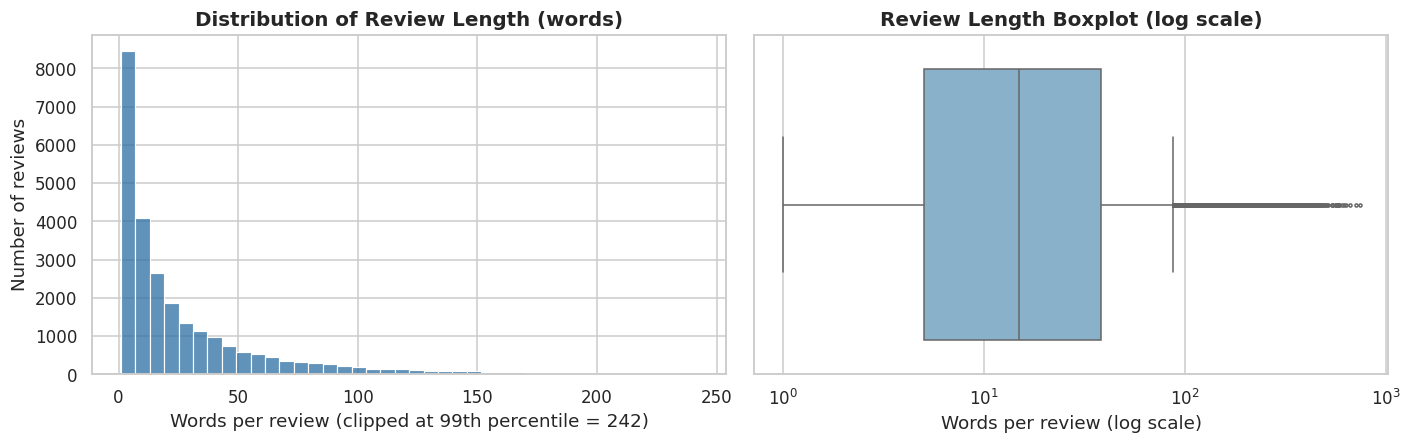

Mean 32.4 words vs median 15 words
25.2% of reviews have <= 5 words;  18.8% have >= 50 words.


In [9]:
corpus["word_count"] = corpus["text_light"].str.split().str.len()
corpus["char_count"] = corpus["text_light"].str.len()

len_stats = corpus[["word_count", "char_count"]].agg(["mean", "median", "min", "max"]).round(1).T
display(len_stats)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
cap = corpus["word_count"].quantile(0.99)
sns.histplot(corpus.loc[corpus["word_count"] <= cap, "word_count"], bins=40, color="#2c6fa3", ax=ax[0])
ax[0].set_title("Distribution of Review Length (words)"); ax[0].set_xlabel(f"Words per review (clipped at 99th percentile = {cap:.0f})"); ax[0].set_ylabel("Number of reviews")
sns.boxplot(x=corpus["word_count"], color="#7fb3d5", ax=ax[1], fliersize=2)
ax[1].set_xscale("log"); ax[1].set_title("Review Length Boxplot (log scale)"); ax[1].set_xlabel("Words per review (log scale)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/review_length.png", dpi=150); plt.show()

short_share = (corpus["word_count"] <= 5).mean()*100
long_share  = (corpus["word_count"] >= 50).mean()*100
print(f"Mean {corpus['word_count'].mean():.1f} words vs median {corpus['word_count'].median():.0f} words")
print(f"{short_share:.1f}% of reviews have <= 5 words;  {long_share:.1f}% have >= 50 words.")

In [10]:
skew = "right-skewed (a few very long reviews pull the mean above the median)" if corpus["word_count"].mean() > corpus["word_count"].median() else "not strongly right-skewed"
display(Markdown(f"""**Interpretation (from the numbers above).** Review length is {skew}. The median review has **{corpus['word_count'].median():.0f} words** while the mean is **{corpus['word_count'].mean():.1f}**, and **{short_share:.1f}%** of reviews are 5 words or fewer. Very short reviews carry little text signal, so we later check whether sentiment agreement depends on review length (Section 24). We make no claim here about *why* guests write short or long reviews."""))

**Interpretation (from the numbers above).** Review length is right-skewed (a few very long reviews pull the mean above the median). The median review has **15 words** while the mean is **32.4**, and **25.2%** of reviews are 5 words or fewer. Very short reviews carry little text signal, so we later check whether sentiment agreement depends on review length (Section 24). We make no claim here about *why* guests write short or long reviews.

## Section 7 — Word Frequency Analysis

We count every token in the processed corpus with `collections.Counter`. Stop-words are already removed; negations are kept (so *not* may appear in the list). A short list of **filler words** (generic verbs/adverbs such as *make, also, book, get, go*) is excluded from the displayed top-20 so the chart shows content words; the full counts still include them (see `word_freq`).

Total tokens: 483,068 | Unique words: 16,122


,Rank,Word,Frequency,% of all tokens
0,1,room,14400,2.98
1,2,good,13450,2.78
2,3,stay,12159,2.52
3,4,hotel,11205,2.32
4,5,not,10135,2.10
5,6,staff,8306,1.72
6,7,service,8228,1.70
7,8,experience,5839,1.21
8,9,clean,5268,1.09
9,10,place,4027,0.83


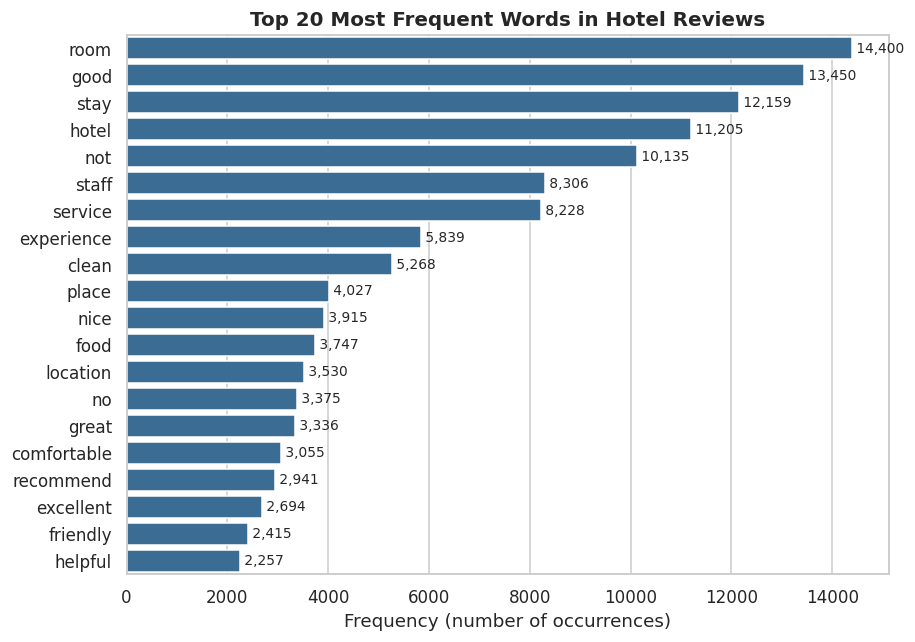

In [11]:
all_tokens = [w for toks in corpus["tokens"] for w in toks]
word_freq  = Counter(all_tokens)
print(f"Total tokens: {len(all_tokens):,} | Unique words: {len(word_freq):,}")

FILLER = {"make", "also", "book", "get", "got", "go", "would", "could", "even", "really", "one", "u", "us", "much", "lot", "like", "well", "overall", "take", "come", "say", "see", "give", "back"}
top_counts = [(w, c) for w, c in word_freq.most_common() if w not in FILLER][:20]     # filler words excluded from the display
top20 = pd.DataFrame(top_counts, columns=["Word", "Frequency"])
top20.insert(0, "Rank", range(1, 21))
top20["% of all tokens"] = (top20["Frequency"] / len(all_tokens) * 100).round(2)
display(top20)

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.barplot(data=top20, y="Word", x="Frequency", color="#2c6fa3", ax=ax)
for i, v in enumerate(top20["Frequency"]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title("Top 20 Most Frequent Words in Hotel Reviews"); ax.set_xlabel("Frequency (number of occurrences)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/top20_words.png", dpi=150); plt.show()

In [12]:
display(Markdown("**Main recurring themes (taken from the actual top-20 list):** " + ", ".join(f"*{w}* ({f:,})" for w, f in word_freq.most_common(10)) +
 ". Words that describe the product (e.g. room, staff, service) and words that carry an evaluation (e.g. good, nice, clean) dominate, so reviews are mostly short evaluative statements about core hotel elements. Frequency alone does not tell us whether a word is used positively or negatively; that comes from the sentiment sections."))

**Main recurring themes (taken from the actual top-20 list):** *room* (14,400), *good* (13,450), *stay* (12,159), *hotel* (11,205), *not* (10,135), *staff* (8,306), *service* (8,228), *experience* (5,839), *clean* (5,268), *place* (4,027). Words that describe the product (e.g. room, staff, service) and words that carry an evaluation (e.g. good, nice, clean) dominate, so reviews are mostly short evaluative statements about core hotel elements. Frequency alone does not tell us whether a word is used positively or negatively; that comes from the sentiment sections.

## Section 8 — Bigram and Trigram Analysis

Single words lose context: *clean* alone does not say what was clean, and *not* alone says nothing. **Bigrams** (2-word phrases) and **trigrams** (3-word phrases) keep context, e.g. *not clean* vs *very clean*. They are generated from the processed token lists, so a phrase is two/three **consecutive kept words** (stop-words between them were removed).

,Rank,Bigram,Frequency,Trigram,Frequency
0,1,good service,1351,would definitely recommend,295
1,2,room clean,1211,would not recommend,291
2,3,well maintain,1077,room clean comfortable,285
3,4,highly recommend,1071,clean well maintain,228
4,5,clean room,815,comfortable well maintain,228
5,6,stay hotel,813,staff friendly helpful,189
6,7,room service,781,clean comfortable well,188
7,8,place stay,772,not recommend hotel,168
8,9,room good,689,ac not work,165
9,10,not work,689,good place stay,159


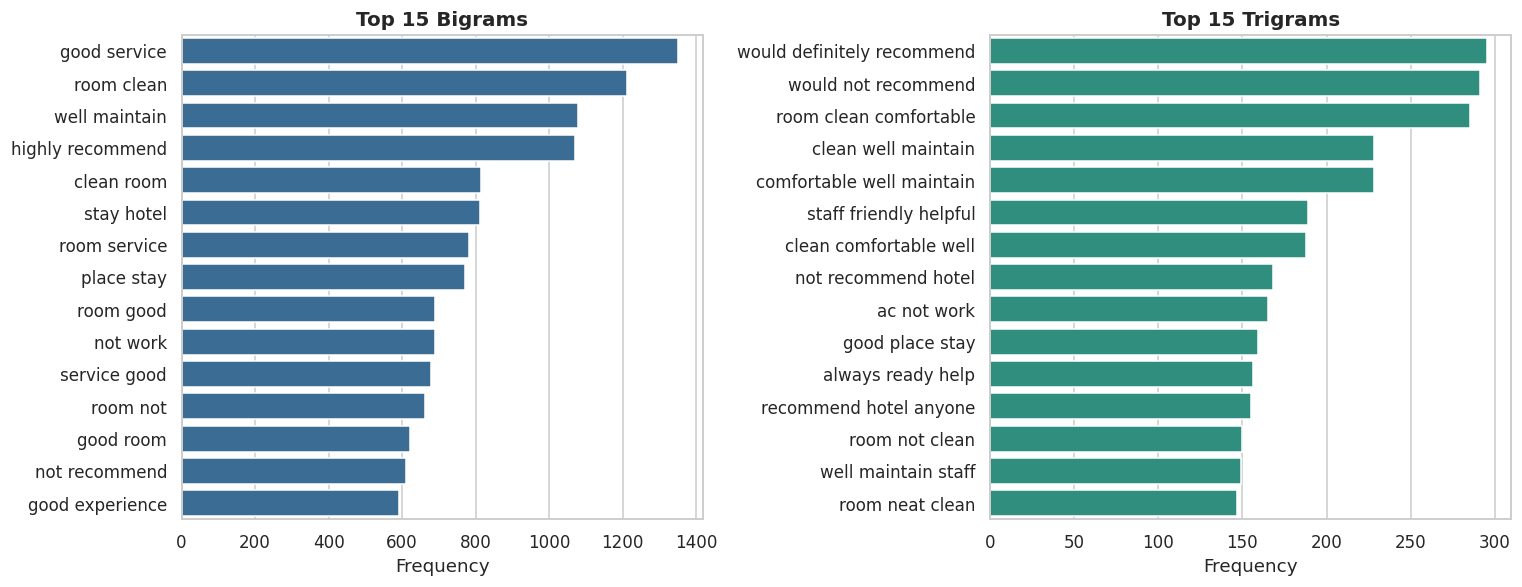

In [13]:
def ngram_counter(token_lists, n):
    c = Counter()
    for toks in token_lists:
        c.update(zip(*[toks[i:] for i in range(n)]))
    return c

bi_freq = ngram_counter(corpus["tokens"], 2)
tri_freq = ngram_counter(corpus["tokens"], 3)

top_bi  = pd.DataFrame([(" ".join(k), v) for k, v in bi_freq.most_common(15)],  columns=["Bigram", "Frequency"])
top_tri = pd.DataFrame([(" ".join(k), v) for k, v in tri_freq.most_common(15)], columns=["Trigram", "Frequency"])
display(pd.concat([top_bi.rename_axis("Rank").reset_index().assign(Rank=lambda d: d.Rank+1),
                   top_tri], axis=1))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.barplot(data=top_bi,  y="Bigram",  x="Frequency", color="#2c6fa3", ax=ax[0]); ax[0].set_title("Top 15 Bigrams")
sns.barplot(data=top_tri, y="Trigram", x="Frequency", color="#1f9e89", ax=ax[1]); ax[1].set_title("Top 15 Trigrams")
for a in ax: a.set_ylabel(""); a.set_xlabel("Frequency")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/top_bigrams_trigrams.png", dpi=150); plt.show()

**Why phrases are more meaningful than single words:** they show *what* is being evaluated and *how* (aspect + opinion), they preserve negation ("not clean"), and they are directly usable as themes for the pattern analysis in later sections.

## Section 9 — Word Cloud

For the cloud we additionally drop a small list of **generic words** (e.g. *hotel, stay, place*) that appear in almost every review and would crowd out informative words. They stay in the frequency analysis above.

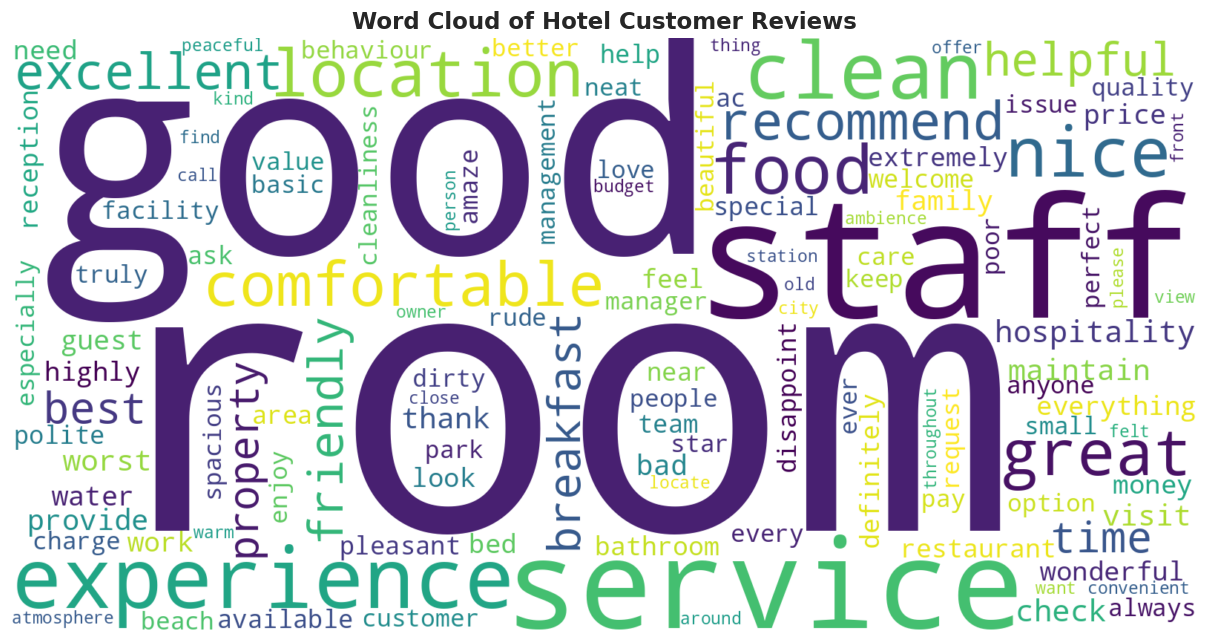

In [14]:
GENERIC = {"hotel", "stay", "place", "one", "get", "got", "go", "went", "also", "would", "could", "even", "really",
           "u", "us", "much", "lot", "like", "take", "make", "come", "say", "see", "give", "back", "day", "night"}
cloud_freq = {w: f for w, f in word_freq.items() if w not in GENERIC and w not in NEGATIONS and w not in FILLER}

wc = WordCloud(width=1600, height=800, background_color="white", colormap="viridis",
               max_words=120, collocations=False, random_state=42).generate_from_frequencies(cloud_freq)
plt.figure(figsize=(12, 6)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
plt.title("Word Cloud of Hotel Customer Reviews", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/word_cloud.png", dpi=150); plt.show()
_ = wc.to_file(f"{OUT_DIR}/word_cloud_clean.png")

**How to read it:** larger words are more frequent. The cloud is a quick visual summary of the vocabulary; it is a **complement** to the frequency table and bar chart, not a replacement — it gives no exact counts and no sentiment direction.

## Section 10 — Review Rating Preparation

Sentiment is evaluated against the **individual** review rating (`individual_review_rating`), *not* the hotel's overall `customer_rating`. First we inspect which scales are present — we do not assume.

In [15]:
rr, rn, rs = COL["rating_raw"], COL["rating_norm"], COL["rating_scale"]
print("rating_scale values:"); display(df[rs].value_counts(dropna=False).to_frame("records"))
print("Raw rating range per scale:")
display(df.groupby(rs)[rr].agg(["count", "min", "max"]))

# Rule: ratings recorded on a 10-point scale are halved; 5-point ratings are left unchanged.
def to_5pt(row_rating, scale):
    if pd.isna(row_rating): return np.nan
    return row_rating / 2 if str(scale).startswith("10-point") else row_rating

df["review_rating_5"] = [to_5pt(r, s) for r, s in zip(df[rr], df[rs])]

# ---- Validation against the existing rating_norm ----
both = df[[rr, "review_rating_5", rn, rs]].dropna()
print(f"\nrow-by-row agreement with existing rating_norm: {(np.isclose(both['review_rating_5'], both[rn])).mean()*100:.2f}%")
five = df[df[rs] == "5-point"]
print(f"5-point rows unchanged by the transformation: {(np.isclose(five['review_rating_5'], five[rr])).mean()*100:.2f}% (n={len(five):,})")
print(f"Max review_rating_5 = {df['review_rating_5'].max()}, min = {df['review_rating_5'].min()}  (all should be within 0-5)")
odd = df[(df[rs].astype(str).str.startswith("10-point")) & (df[rr] <= 5)]
print(f"Note: {len(odd)} records are tagged 10-point (Booking.com / freecancellations.com-type sources) but have raw values <= 5. "
      f"We follow the recorded scale and halve them ({len(odd)/len(df)*100:.2f}% of all records), same as Review 1's rating_norm.")

corpus["review_rating_5"] = df.loc[in_corpus, "review_rating_5"].values
corpus = corpus[corpus["review_rating_5"].notna()].reset_index(drop=True)
print(f"\nCorpus with a valid rating: {len(corpus):,} reviews")

rating_scale values:


,records
rating_scale,
5-point,29537
10-point,342
10-point-inferred,85
Unknown,23


Raw rating range per scale:


,count,min,max
rating_scale,,,
10-point,342,1.0,10.0
10-point-inferred,85,5.4,10.0
5-point,29537,0.5,5.0
Unknown,0,NaN,NaN



row-by-row agreement with existing rating_norm: 100.00%
5-point rows unchanged by the transformation: 100.00% (n=29,537)
Max review_rating_5 = 5.0, min = 0.5  (all should be within 0-5)
Note: 23 records are tagged 10-point (Booking.com / freecancellations.com-type sources) but have raw values <= 5. We follow the recorded scale and halve them (0.08% of all records), same as Review 1's rating_norm.

Corpus with a valid rating: 26,175 reviews


**Transformation documented:** `review_rating_5 = rating / 2` for 10-point sources, otherwise unchanged. It reproduces Review 1's `rating_norm` exactly and leaves every 5-point value untouched, so it does not distort the existing data.

## Section 11 — Rating-Based Sentiment Label

| Rating (5-pt) | Reference sentiment |
|---|---|
| < 3.0 | Negative |
| 3.0 to < 4.0 | Neutral |
| ≥ 4.0 | Positive |

> This is a **rating-based reference sentiment**, *not* perfect ground truth: a number and the words that go with it can disagree (e.g. 5 stars with a complaint inside the text).

,Reviews,Percent
rating_sentiment,,
Negative,5586,21.3
Neutral,1277,4.9
Positive,19312,73.8


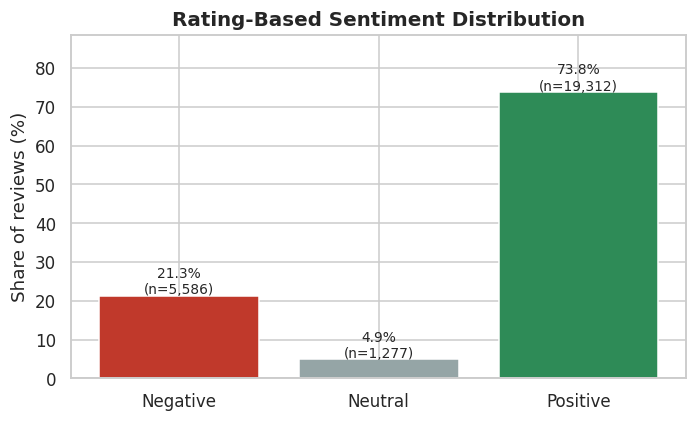

In [16]:
corpus["rating_sentiment"] = np.select(
    [corpus["review_rating_5"] < 3.0, corpus["review_rating_5"] < 4.0], ["Negative", "Neutral"], default="Positive")

rs_counts = corpus["rating_sentiment"].value_counts().reindex(SENT_ORDER)
rs_tbl = pd.DataFrame({"Reviews": rs_counts, "Percent": (rs_counts / rs_counts.sum() * 100).round(1)})
display(rs_tbl)

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(rs_tbl.index, rs_tbl["Percent"], color=[SENT_COLORS[s] for s in rs_tbl.index])
for b, (n, p) in zip(bars, zip(rs_tbl["Reviews"], rs_tbl["Percent"])):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.5, f"{p:.1f}%\n(n={n:,})", ha="center", fontsize=9)
ax.set_title("Rating-Based Sentiment Distribution"); ax.set_ylabel("Share of reviews (%)"); ax.set_ylim(0, rs_tbl["Percent"].max()*1.2)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rating_sentiment_distribution.png", dpi=150); plt.show()

## Section 12 — VADER Sentiment Analysis

**VADER** is a lexicon-based sentiment scorer designed for short, informal text. It returns `neg`, `neu`, `pos` proportions and a `compound` score from −1 to +1. We run it on `text_light` (not the stop-word-stripped text) because VADER uses negations, capitals, punctuation and emoji.

Standard thresholds: compound ≥ 0.05 → **Positive**; ≤ −0.05 → **Negative**; otherwise **Neutral**.

In [17]:
sia = SentimentIntensityAnalyzer()
scores = corpus["text_light"].apply(sia.polarity_scores).apply(pd.Series)
corpus["vader_negative"] = scores["neg"]; corpus["vader_neutral"] = scores["neu"]; corpus["vader_positive"] = scores["pos"]
corpus["vader_compound"] = scores["compound"]

corpus["vader_sentiment"] = np.select(
    [corpus["vader_compound"] >= 0.05, corpus["vader_compound"] <= -0.05], ["Positive", "Negative"], default="Neutral")

# Real examples: 3 per VADER class, random but reproducible
ex_rows = pd.concat([corpus[(corpus["vader_sentiment"] == s) & corpus["text_light"].str.len().between(40, 140)].sample(3, random_state=3)
                     for s in ["Positive", "Neutral", "Negative"]])
display(ex_rows.assign(Review=ex_rows["text_light"])[["Review", "review_rating_5", "vader_compound", "vader_sentiment"]]
        .rename(columns={"review_rating_5": "Rating (5-pt)", "vader_compound": "Compound", "vader_sentiment": "VADER Sentiment"}).round(3))

,Review,Rating (5-pt),Compound,VADER Sentiment
1311,All good miss muskan was service good great smile and food was nice,5.0,0.927,Positive
20225,It was a great experience from the staffs affordable room thank you,2.0,0.765,Positive
17083,Acha place hai. and people are amazing. They are helpful and responsive.,5.0,0.844,Positive
19551,Building was very old and vibe was okok compared to other properties and standards Would not visit again,2.0,0.000,Neutral
8075,If you want to stay you can stay somewhere nearby but never prefer this particular place.worst place I've ...,1.0,0.039,Neutral
13924,This property is non maintain and property pic is not realistic,1.0,0.000,Neutral
25238,Room not net clear cleaning very bad boost,1.0,-0.459,Negative
22321,Pathetic U will find used condom Dirty walls Stained linen It’s not hotel,1.0,-0.765,Negative
14099,Rooms are good but not enjoyed the in-house restaurant food.,4.0,-0.382,Negative


## Section 13 — VADER Sentiment Distribution

,Reviews,Percent
vader_sentiment,,
Negative,4869,18.6
Neutral,1338,5.1
Positive,19968,76.3


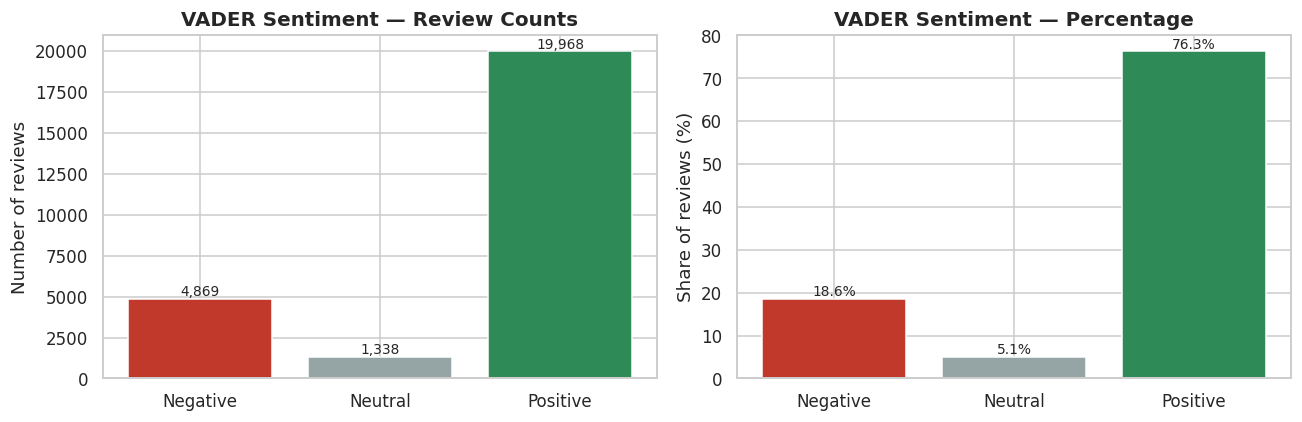

**Interpretation.** According to VADER, **76.3%** of reviews are positive, **5.1%** neutral and **18.6%** negative, so the corpus is **strongly positive** by text sentiment. The rating-based reference shows **73.8%** positive, **4.9%** neutral and **21.3%** negative; the next two sections compare the two views.

In [18]:
v_counts = corpus["vader_sentiment"].value_counts().reindex(SENT_ORDER)
v_pct = (v_counts / v_counts.sum() * 100).round(1)
display(pd.DataFrame({"Reviews": v_counts, "Percent": v_pct}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(v_counts.index, v_counts.values, color=[SENT_COLORS[s] for s in v_counts.index])
ax[0].set_title("VADER Sentiment — Review Counts"); ax[0].set_ylabel("Number of reviews")
for i, v in enumerate(v_counts.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax[1].bar(v_pct.index, v_pct.values, color=[SENT_COLORS[s] for s in v_pct.index])
ax[1].set_title("VADER Sentiment — Percentage"); ax[1].set_ylabel("Share of reviews (%)")
for i, v in enumerate(v_pct.values): ax[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/vader_sentiment_distribution.png", dpi=150); plt.show()

pos_p, neu_p, neg_p = v_pct["Positive"], v_pct["Neutral"], v_pct["Negative"]
if pos_p >= 60: tone = "strongly positive"
elif neg_p >= 40: tone = "negative-heavy"
elif abs(pos_p - neg_p) <= 10: tone = "roughly balanced"
else: tone = "moderately positive" if pos_p > neg_p else "moderately negative"
display(Markdown(f"**Interpretation.** According to VADER, **{pos_p}%** of reviews are positive, **{neu_p}%** neutral and **{neg_p}%** negative, so the corpus is **{tone}** by text sentiment. The rating-based reference shows **{rs_tbl.loc['Positive','Percent']}%** positive, **{rs_tbl.loc['Neutral','Percent']}%** neutral and **{rs_tbl.loc['Negative','Percent']}%** negative; the next two sections compare the two views."))

## Section 14 — Sentiment vs Rating Comparison

Cross-tabulating the rating-based reference label with the VADER label. Rows = what the star rating says, columns = what the text says.

1) Counts:


VADER (columns),Negative,Neutral,Positive
Rating-based (rows),,,
Negative,4343,406,837
Neutral,299,186,792
Positive,227,746,18339


2) Row percentages (of each rating-based class, how VADER labelled them):


VADER (columns),Negative,Neutral,Positive
Rating-based (rows),,,
Negative,77.7,7.3,15.0
Neutral,23.4,14.6,62.0
Positive,1.2,3.9,95.0


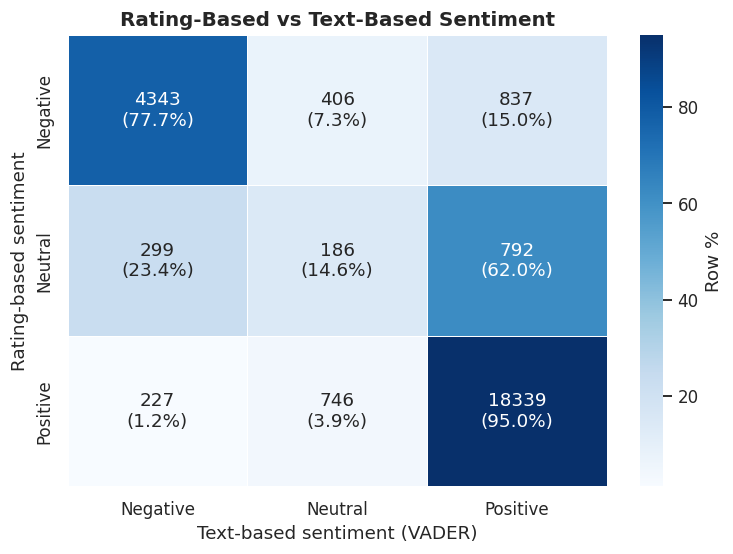

In [19]:
ct = pd.crosstab(corpus["rating_sentiment"], corpus["vader_sentiment"]).reindex(index=SENT_ORDER, columns=SENT_ORDER, fill_value=0)
ct.index.name = "Rating-based (rows)"; ct.columns.name = "VADER (columns)"
print("1) Counts:"); display(ct)
ct_pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
print("2) Row percentages (of each rating-based class, how VADER labelled them):"); display(ct_pct)

annot = ct.astype(str) + "\n(" + ct_pct.astype(str) + "%)"
plt.figure(figsize=(7, 5.2))
sns.heatmap(ct_pct, annot=annot, fmt="", cmap="Blues", cbar_kws={"label": "Row %"}, linewidths=.5)
plt.title("Rating-Based vs Text-Based Sentiment"); plt.xlabel("Text-based sentiment (VADER)"); plt.ylabel("Rating-based sentiment")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rating_vs_vader_heatmap.png", dpi=150); plt.show()

## Section 15 — Sentiment Evaluation

VADER (prediction) is evaluated against the rating-based reference (actual). VADER is an unsupervised lexicon method — nothing is trained — so there is no train/test leakage.

> **Rating-based sentiment is treated as a reference/proxy label rather than absolute ground truth.** The metrics therefore measure *agreement with ratings*, not absolute correctness.

In [20]:
from sklearn.metrics import roc_auc_score
y_true, y_pred = corpus["rating_sentiment"], corpus["vader_sentiment"]

acc = accuracy_score(y_true, y_pred)
mp, mr, mf1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", labels=SENT_ORDER, zero_division=0)
wf1 = f1_score(y_true, y_pred, average="weighted", labels=SENT_ORDER, zero_division=0)
kappa = cohen_kappa_score(y_true, y_pred)
majority_acc = y_true.value_counts(normalize=True).max()
majority_cls = y_true.value_counts().idxmax()

# Extra context: can the compound score separate clearly negative (<=2) from clearly positive (>=4) ratings?
clear = corpus[(corpus["review_rating_5"] <= 2) | (corpus["review_rating_5"] >= 4)]
auc = roc_auc_score((clear["review_rating_5"] >= 4).astype(int), clear["vader_compound"])
rho = corpus[["vader_compound", "review_rating_5"]].corr(method="spearman").iloc[0, 1]

metrics = pd.DataFrame({"Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1",
                                   "Cohen's kappa (agreement beyond chance)", f"Baseline: always predict '{majority_cls}'",
                                   "Spearman corr (compound vs rating)", "ROC-AUC (rating<=2 vs >=4, using compound)"],
                        "Value": [acc, mp, mr, mf1, wf1, kappa, majority_acc, rho, auc]}).round(4)
display(metrics)

print("Classification report (rows = reference label, VADER = prediction):")
report = classification_report(y_true, y_pred, labels=SENT_ORDER, zero_division=0, output_dict=True)
rep_df = pd.DataFrame(report).T.round(3); display(rep_df)
print(classification_report(y_true, y_pred, labels=SENT_ORDER, zero_division=0))

,Metric,Value
0,Accuracy,0.8737
1,Macro Precision,0.6498
2,Macro Recall,0.6243
3,Macro F1,0.6356
4,Weighted F1,0.8732
5,Cohen's kappa (agreement beyond chance),0.6801
6,Baseline: always predict 'Positive',0.7378
7,Spearman corr (compound vs rating),0.6157
8,"ROC-AUC (rating<=2 vs >=4, using compound)",0.9501


Classification report (rows = reference label, VADER = prediction):


,precision,recall,f1-score,support
Negative,0.892,0.777,0.831,5586.000
Neutral,0.139,0.146,0.142,1277.000
Positive,0.918,0.950,0.934,19312.000
accuracy,0.874,0.874,0.874,0.874
macro avg,0.650,0.624,0.636,26175.000
weighted avg,0.875,0.874,0.873,26175.000


              precision    recall  f1-score   support

    Negative       0.89      0.78      0.83      5586
     Neutral       0.14      0.15      0.14      1277
    Positive       0.92      0.95      0.93     19312

    accuracy                           0.87     26175
   macro avg       0.65      0.62      0.64     26175
weighted avg       0.87      0.87      0.87     26175



,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,4343,406,837
Actual Neutral,299,186,792
Actual Positive,227,746,18339


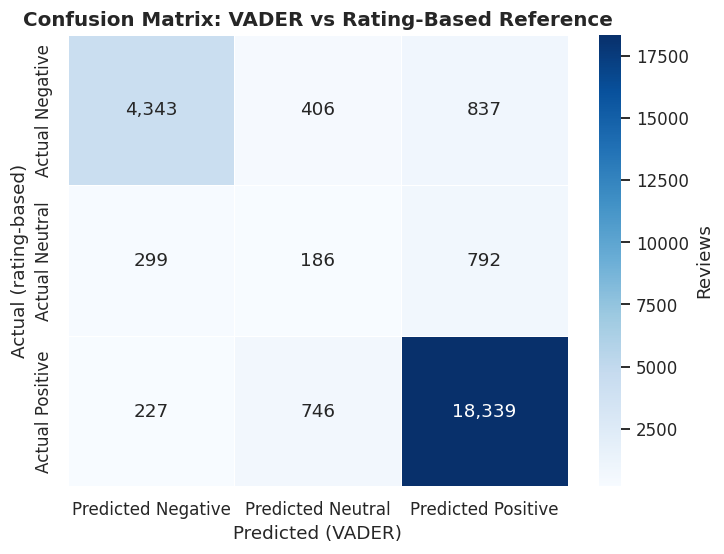

In [21]:
cm = confusion_matrix(y_true, y_pred, labels=SENT_ORDER)
cm_df = pd.DataFrame(cm, index=[f"Actual {s}" for s in SENT_ORDER], columns=[f"Predicted {s}" for s in SENT_ORDER])
display(cm_df)
plt.figure(figsize=(6.8, 5.2))
sns.heatmap(cm_df, annot=True, fmt=",d", cmap="Blues", linewidths=.5, cbar_kws={"label": "Reviews"})
plt.title("Confusion Matrix: VADER vs Rating-Based Reference"); plt.ylabel("Actual (rating-based)"); plt.xlabel("Predicted (VADER)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=150); plt.show()

### Section 15b — Evaluation on the clear-signal reviews (Positive vs Negative only)

The three-class result is dragged down by the Neutral class: 3-star reviews are genuinely ambiguous, and VADER's neutral band (compound between -0.05 and 0.05) is very narrow. To show how well text sentiment works **where the rating signal is clear**, we repeat the evaluation on rating-Negative and rating-Positive reviews only (3-star reviews excluded):

- **Forced binary:** VADER compound ≥ 0.05 → Positive, otherwise Negative.
- **Decisive-only:** reviews VADER labels Neutral are dropped, and the share of reviews kept (coverage) is reported.

The rating-based label is still a reference/proxy, not absolute truth.

,n_reviews,accuracy,majority_baseline,macro_precision,macro_recall,macro_f1,f1_negative,f1_positive,recall_negative,precision_negative,kappa,roc_auc,coverage_pct
forced_binary,24898.0,0.9273,0.7756,0.8932,0.8999,0.8965,0.8399,0.9530,0.8502,0.8300,0.7929,0.9500,NaN
decisive_only,23746.0,0.9552,0.7819,0.9533,0.9131,0.9313,0.8909,0.9718,0.8384,0.9503,0.8628,0.9529,95.3731


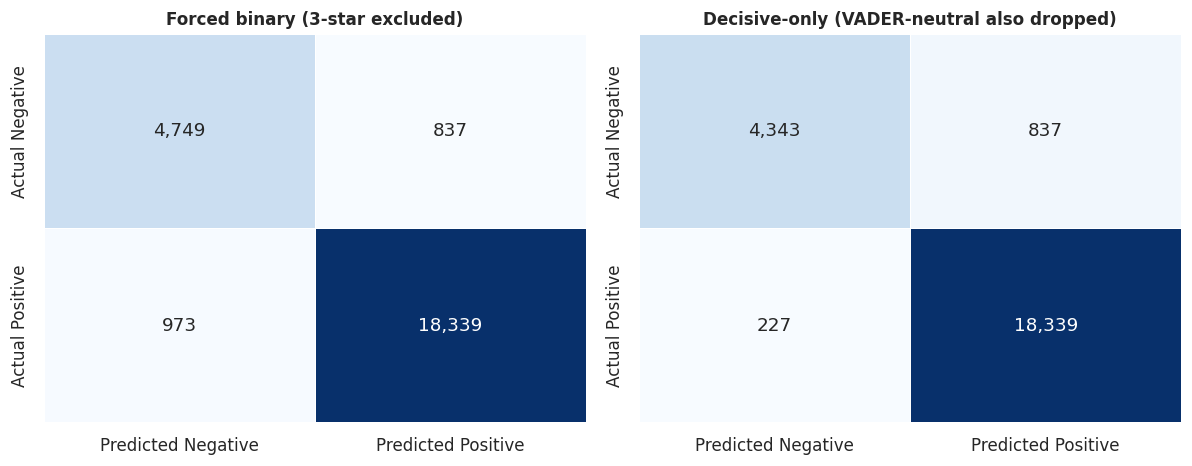

**Interpretation.** On the 24,898 reviews with a clear rating signal (1-2 or 4-5 stars), VADER reaches **92.7% accuracy** and **macro-F1 0.896** (majority baseline 77.6%, kappa 0.79, ROC-AUC 0.95). Negative-class F1 is 0.840 and Positive-class F1 is 0.953.
If VADER-neutral reviews are set aside (95.4% of the clear-signal reviews are kept), accuracy is **95.5%** and macro-F1 **0.931**.
The weak three-class macro-F1 (Section 15) is therefore driven mostly by the ambiguous Neutral class rather than by an inability to separate positive from negative text. This is an observed result against a rating-based *proxy*, not proof of correctness.

In [22]:
clear_df = corpus[corpus["rating_sentiment"].isin(["Negative", "Positive"])].copy()
BIN = ["Negative", "Positive"]
clear_df["vader_binary"] = np.where(clear_df["vader_compound"] >= 0.05, "Positive", "Negative")      # forced binary
decisive = clear_df[clear_df["vader_sentiment"] != "Neutral"]                                       # decisive-only

def bin_eval(frame, pred_col):
    yt, yp = frame["rating_sentiment"], frame[pred_col]
    p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=BIN, zero_division=0)
    return {"n_reviews": int(len(frame)), "accuracy": float(accuracy_score(yt, yp)),
            "majority_baseline": float(yt.value_counts(normalize=True).max()),
            "macro_precision": float(p.mean()), "macro_recall": float(r.mean()), "macro_f1": float(f.mean()),
            "f1_negative": float(f[0]), "f1_positive": float(f[1]), "recall_negative": float(r[0]), "precision_negative": float(p[0]),
            "kappa": float(cohen_kappa_score(yt, yp)),
            "roc_auc": float(roc_auc_score((frame["rating_sentiment"] == "Positive").astype(int), frame["vader_compound"]))}

bin_forced = bin_eval(clear_df, "vader_binary")
bin_decisive = bin_eval(decisive, "vader_sentiment")
bin_decisive["coverage_pct"] = 100 * len(decisive) / len(clear_df)
bin_metrics = {"forced_binary": bin_forced, "decisive_only": bin_decisive}

tbl = pd.DataFrame(bin_metrics).T.round(4)
display(tbl)
pd.DataFrame(bin_metrics).T.to_csv(f"{OUT_DIR}/binary_evaluation_metrics.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax_, (title, frame, col) in zip(axes, [("Forced binary (3-star excluded)", clear_df, "vader_binary"),
                                          ("Decisive-only (VADER-neutral also dropped)", decisive, "vader_sentiment")]):
    cmb = pd.DataFrame(confusion_matrix(frame["rating_sentiment"], frame[col], labels=BIN),
                       index=[f"Actual {s}" for s in BIN], columns=[f"Predicted {s}" for s in BIN])
    sns.heatmap(cmb, annot=True, fmt=",d", cmap="Blues", linewidths=.5, cbar=False, ax=ax_)
    ax_.set_title(title, fontsize=11)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix_binary.png", dpi=150, bbox_inches="tight"); plt.show()

display(Markdown(f"""**Interpretation.** On the {bin_forced['n_reviews']:,} reviews with a clear rating signal (1-2 or 4-5 stars), VADER reaches **{bin_forced['accuracy']*100:.1f}% accuracy** and **macro-F1 {bin_forced['macro_f1']:.3f}** (majority baseline {bin_forced['majority_baseline']*100:.1f}%, kappa {bin_forced['kappa']:.2f}, ROC-AUC {bin_forced['roc_auc']:.2f}). Negative-class F1 is {bin_forced['f1_negative']:.3f} and Positive-class F1 is {bin_forced['f1_positive']:.3f}.
If VADER-neutral reviews are set aside ({bin_decisive['coverage_pct']:.1f}% of the clear-signal reviews are kept), accuracy is **{bin_decisive['accuracy']*100:.1f}%** and macro-F1 **{bin_decisive['macro_f1']:.3f}**.
The weak three-class macro-F1 (Section 15) is therefore driven mostly by the ambiguous Neutral class rather than by an inability to separate positive from negative text. This is an observed result against a rating-based *proxy*, not proof of correctness."""))

## Section 16 — Interpret Sentiment Evaluation

*Findings* below are computed from the data. *Possible explanations* are hypotheses commonly given in the literature and are **not tested** here.

In [23]:
per_cls = pd.DataFrame({c: report[c] for c in SENT_ORDER}).T
best_cls  = per_cls["f1-score"].idxmax();  worst_cls = per_cls["f1-score"].idxmin()
cm_off = cm_df.copy().astype(float)
for i, s in enumerate(SENT_ORDER): cm_off.iloc[i, i] = -1          # ignore the diagonal
r, c = np.unravel_index(np.argmax(cm_off.values), cm_off.shape)
rating_pos_to_neg = ct_pct.loc["Positive", "Negative"]; rating_neg_to_pos = ct_pct.loc["Negative", "Positive"]
neu_correct = ct_pct.loc["Neutral", "Neutral"]

display(Markdown(f"""### Actual findings
- **Overall agreement:** accuracy = **{acc*100:.1f}%**, macro-F1 = **{mf1:.3f}**, weighted-F1 = **{wf1:.3f}**. Cohen's kappa = **{kappa:.3f}** (agreement beyond chance). For context, always predicting the majority class ('{majority_cls}') would give **{majority_acc*100:.1f}%** accuracy, so accuracy must be read together with macro-F1 because the classes are imbalanced.
- **Best-detected class:** **{best_cls}** (F1 = {per_cls.loc[best_cls,'f1-score']:.3f}). **Hardest class:** **{worst_cls}** (F1 = {per_cls.loc[worst_cls,'f1-score']:.3f}).
- **Largest confusion:** reviews that are *{cm_df.index[r].replace('Actual ','')}* by rating but *{cm_df.columns[c].replace('Predicted ','')}* by VADER ({int(cm_df.iloc[r, c]):,} reviews).
- Only **{neu_correct:.1f}%** of rating-neutral (3-star) reviews are labelled Neutral by VADER; **{rating_neg_to_pos:.1f}%** of rating-negative reviews are labelled Positive and **{rating_pos_to_neg:.1f}%** of rating-positive reviews are labelled Negative.
- The compound score still ranks reviews sensibly: Spearman correlation with rating = **{rho:.3f}**; ROC-AUC for separating ≤2-star from ≥4-star reviews = **{auc:.3f}**.

### Possible explanations (hypotheses, not tested)
- Guests give high ratings but mention small complaints (and the reverse), so the number and the words disagree.
- Mixed reviews contain both praise and complaints, which the single compound score averages out.
- Sarcasm, context and domain language (e.g. "decent", "average", "ok") are handled poorly by a general-purpose lexicon.
- Very short reviews ("Good", "Ok") give VADER little to work with; 3-star reviews are inherently ambiguous.
- Mixed-language / transliterated text (e.g. Hindi written in English letters) cannot be understood by an English lexicon."""))

print("Examples of disagreement (real reviews):")
d1 = corpus[(corpus["review_rating_5"] >= 4.5) & (corpus["vader_sentiment"] == "Negative") & corpus["text_light"].str.len().between(60, 260)].sort_values("vader_compound").head(3)
d2 = corpus[(corpus["review_rating_5"] <= 1.5) & (corpus["vader_sentiment"] == "Positive") & corpus["text_light"].str.len().between(60, 260)].sort_values("vader_compound", ascending=False).head(3)
display(pd.concat([d1.assign(Case="High rating, negative text"), d2.assign(Case="Low rating, positive text")])[["Case", "review_rating_5", "vader_compound", "text_light"]].round(3))

### Actual findings
- **Overall agreement:** accuracy = **87.4%**, macro-F1 = **0.636**, weighted-F1 = **0.873**. Cohen's kappa = **0.680** (agreement beyond chance). For context, always predicting the majority class ('Positive') would give **73.8%** accuracy, so accuracy must be read together with macro-F1 because the classes are imbalanced.
- **Best-detected class:** **Positive** (F1 = 0.934). **Hardest class:** **Neutral** (F1 = 0.142).
- **Largest confusion:** reviews that are *Negative* by rating but *Positive* by VADER (837 reviews).
- Only **14.6%** of rating-neutral (3-star) reviews are labelled Neutral by VADER; **15.0%** of rating-negative reviews are labelled Positive and **1.2%** of rating-positive reviews are labelled Negative.
- The compound score still ranks reviews sensibly: Spearman correlation with rating = **0.616**; ROC-AUC for separating ≤2-star from ≥4-star reviews = **0.950**.

### Possible explanations (hypotheses, not tested)
- Guests give high ratings but mention small complaints (and the reverse), so the number and the words disagree.
- Mixed reviews contain both praise and complaints, which the single compound score averages out.
- Sarcasm, context and domain language (e.g. "decent", "average", "ok") are handled poorly by a general-purpose lexicon.
- Very short reviews ("Good", "Ok") give VADER little to work with; 3-star reviews are inherently ambiguous.
- Mixed-language / transliterated text (e.g. Hindi written in English letters) cannot be understood by an English lexicon.

Examples of disagreement (real reviews):


,Case,review_rating_5,vader_compound,text_light
24821,"High rating, negative text",5.0,-0.813,It’s dirty and full of cockroaches—simply a terrible experience. I do not recommend it! I’d also add that ...
3310,"High rating, negative text",5.0,-0.791,Bad service TV not working Ac remote not working Bad room service
22958,"High rating, negative text",5.0,-0.765,"Colaba ist fantastisch. Die Lage war absolut mega super, das Colaba Viertel ist definitiv mein Still, das ..."
22895,"Low rating, positive text",1.0,0.962,Excellent service nice Staff amazing foodvery good excellent food shradha was nice behavior
16585,"Low rating, positive text",1.0,0.961,Nice hotel in jaipur. Well decorated rooms and facilities. Enjoy best food in this hotel. I like rajasthan...
24219,"Low rating, positive text",1.0,0.954,Excellent place to stay. Their hospitality and services are amazing. Especially the home cooked food and t...


## Section 17 — Positive Review Patterns

Subset: reviews with `vader_sentiment == "Positive"`. We repeat the frequency and n-gram analysis on this subset only.

Positive reviews analysed: 19,968


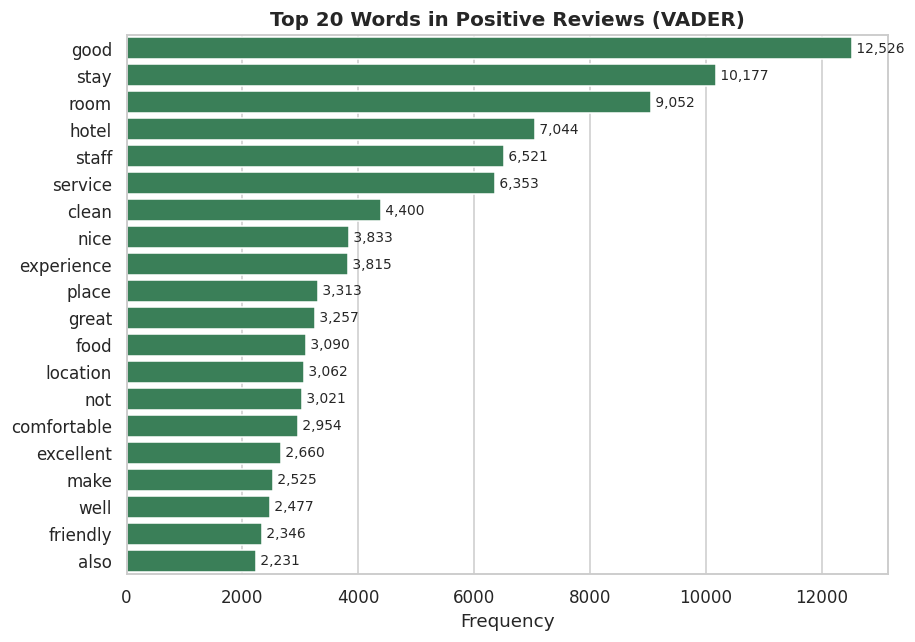

,Bigram,Freq,Trigram,Freq
0,good service,1308,would definitely recommend,295
1,room clean,1143,room clean comfortable,285
2,highly recommend,1062,comfortable well maintain,228
3,well maintain,1036,clean well maintain,222
4,clean room,722,staff friendly helpful,189
5,place stay,709,clean comfortable well,188
6,service good,666,always ready help,156
7,room good,654,good place stay,155
8,stay hotel,607,well maintain staff,148
9,staff friendly,571,room neat clean,142


In [24]:
def subset_counters(mask):
    toks = corpus.loc[mask, "tokens"]
    return Counter(w for t in toks for w in t), ngram_counter(toks, 2), ngram_counter(toks, 3), int(mask.sum())

def plot_top_words(counter, title, color, fname, n=20):
    d = pd.DataFrame(counter.most_common(n), columns=["Word", "Frequency"])
    fig, ax = plt.subplots(figsize=(8.5, 6))
    sns.barplot(data=d, y="Word", x="Frequency", color=color, ax=ax)
    for i, v in enumerate(d["Frequency"]): ax.text(v, i, f" {v:,}", va="center", fontsize=9)
    ax.set_title(title); ax.set_xlabel("Frequency"); ax.set_ylabel("")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.show()
    return d

def ngram_table(bi, tri, n=10):
    return pd.concat([pd.DataFrame([(" ".join(k), v) for k, v in bi.most_common(n)],  columns=["Bigram", "Freq"]),
                      pd.DataFrame([(" ".join(k), v) for k, v in tri.most_common(n)], columns=["Trigram", "Freq"])], axis=1)

pos_words, pos_bi, pos_tri, n_pos = subset_counters(corpus["vader_sentiment"] == "Positive")
print(f"Positive reviews analysed: {n_pos:,}")
pos_top20 = plot_top_words(pos_words, "Top 20 Words in Positive Reviews (VADER)", SENT_COLORS["Positive"], "top20_positive_words.png")
display(ngram_table(pos_bi, pos_tri))

In [25]:
display(Markdown("**Major positive themes (from the data):** top words — " + ", ".join(w for w, _ in pos_words.most_common(10)) +
                 "; top phrases — " + ", ".join(" ".join(k) for k, _ in pos_bi.most_common(6)) +
                 ". Positive reviews are dominated by evaluative words about the *product* (room, staff, service, food, location) and short praise phrases."))

**Major positive themes (from the data):** top words — good, stay, room, hotel, staff, service, clean, nice, experience, place; top phrases — good service, room clean, highly recommend, well maintain, clean room, place stay. Positive reviews are dominated by evaluative words about the *product* (room, staff, service, food, location) and short praise phrases.

## Section 18 — Negative Review Patterns

Subset: reviews with `vader_sentiment == "Negative"`. This section feeds the business recommendations most directly.

Negative reviews analysed: 4,869


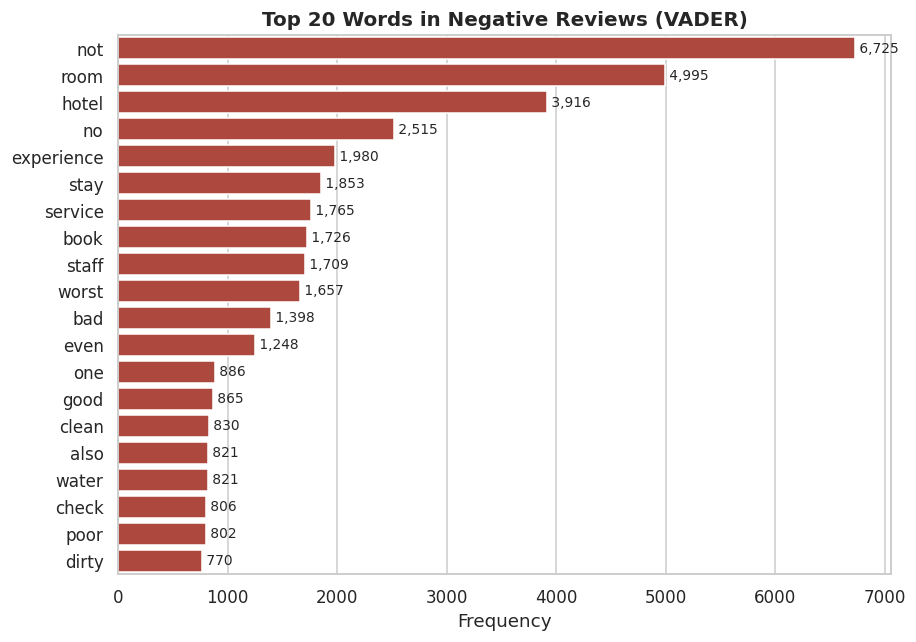

,Bigram,Freq,Trigram,Freq
0,not recommend,541,would not recommend,261
1,not work,521,not recommend hotel,157
2,room not,464,ac not work,132
3,not good,430,room not clean,122
4,worst hotel,371,worst experience ever,98
5,not clean,364,not work properly,97
6,worst experience,348,no hot water,94
7,would not,320,one worst hotel,93
8,not even,317,worst hotel experience,83
9,bad experience,299,worst hotel ever,78


In [26]:
neg_words, neg_bi, neg_tri, n_neg = subset_counters(corpus["vader_sentiment"] == "Negative")
print(f"Negative reviews analysed: {n_neg:,}")
neg_top20 = plot_top_words(neg_words, "Top 20 Words in Negative Reviews (VADER)", SENT_COLORS["Negative"], "top20_negative_words.png")
display(ngram_table(neg_bi, neg_tri))

In [27]:
display(Markdown("**Major complaint signals (from the data):** top words — " + ", ".join(w for w, _ in neg_words.most_common(10)) +
                 "; top phrases — " + ", ".join(" ".join(k) for k, _ in neg_bi.most_common(8)) +
                 ". Note that negations (*not, no*) and neutral nouns (*room, staff*) appear too: a negative review is usually about an ordinary hotel element that went wrong. Section 21 turns these signals into specific, countable pain points."))

**Major complaint signals (from the data):** top words — not, room, hotel, no, experience, stay, service, book, staff, worst; top phrases — not recommend, not work, room not, not good, worst hotel, not clean, worst experience, would not. Note that negations (*not, no*) and neutral nouns (*room, staff*) appear too: a negative review is usually about an ordinary hotel element that went wrong. Section 21 turns these signals into specific, countable pain points.

## Section 19 — Positive vs Negative Comparison

**Theme detection by keyword matching.** We define transparent keyword patterns for common hotel themes and count the *reviews* that mention each theme, split by the VADER class of the whole review. A theme is kept only if it is mentioned in at least `MIN_THEME` reviews, so nothing is reported on thin evidence.

*Limitation:* keyword matching does not understand context (a review labelled Negative may praise the staff and complain about the room; the staff mention is still counted under Negative). Section 20 refines this with sentence-level sentiment for amenities.

Overall: 76.3% positive, 18.6% negative reviews. Themes dropped for < 50 mentions: none


,Theme,Positive Mentions,Neutral Mentions,Negative Mentions,Total Mentions,% of reviews mentioning,% Positive,% Negative,Neg vs overall (pp)
0,Room,6856,259,2567,9682,37.0,70.8,26.5,7.9
1,Staff,6626,111,1769,8506,32.5,77.9,20.8,2.2
2,Service,5466,97,1353,6916,26.4,79.0,19.6,1.0
3,Cleanliness,4896,90,1635,6621,25.3,73.9,24.7,6.1
4,Location,3936,124,576,4636,17.7,84.9,12.4,-6.2
5,Food,3251,85,587,3923,15.0,82.9,15.0,-3.6
6,Price / value,2358,142,1065,3565,13.6,66.1,29.9,11.3
7,Bathroom,902,57,1037,1996,7.6,45.2,52.0,33.4
8,Breakfast,1391,30,333,1754,6.7,79.3,19.0,0.4
9,Bed / bedding,568,35,757,1360,5.2,41.8,55.7,37.1


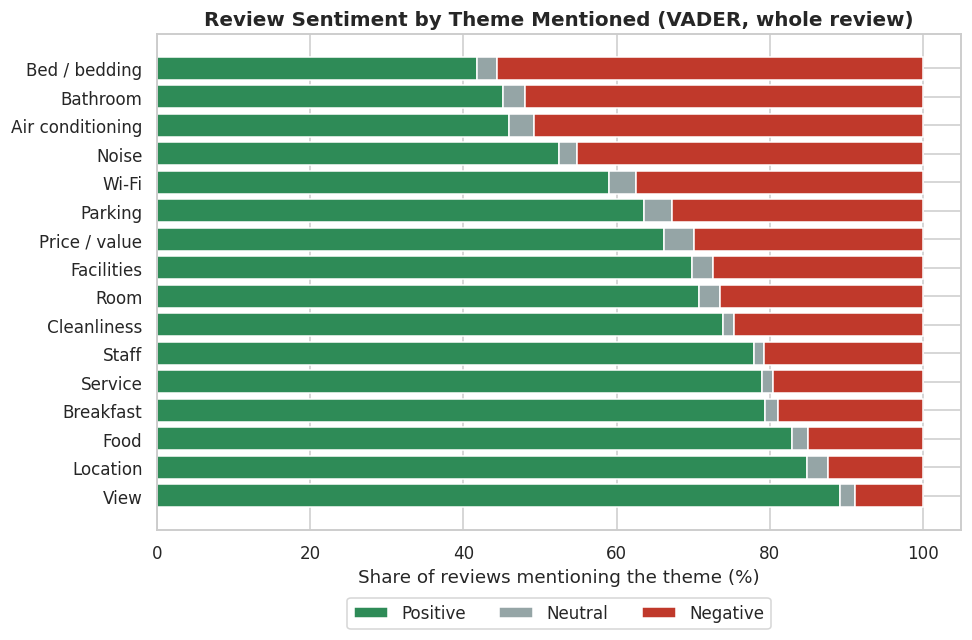

**Basis of this table:** every review that mentions the theme is labelled by the VADER sentiment of the *whole review*. Section 20 instead scores only the *sentences* that mention an amenity, so percentages for the same topic (e.g. Breakfast) differ between the two sections by design.

In [28]:
MIN_THEME = 50
corpus["text_lc"] = corpus["text_light"].str.lower()

THEMES = {
 "Room":             r"\brooms?\b",
 "Staff":            r"\bstaffs?\b|\bemployees?\b|\breception\w*|\bmanager\b|\bcaretaker\b|\bhousekeeping\b|\bwaiters?\b",
 "Service":          r"\bservices?\b",
 "Cleanliness":      r"\bclean\w*|\bdirty\b|\bdirt\b|\bhygien\w*|\btidy\b|\bspotless\b|\bfilth\w*|\bunclean\b|\bsmell\w*|\bstink\w*|\bneat\b",
 "Food":             r"\bfood\b|\bdinner\b|\blunch\b|\bmeals?\b|\bbuffet\b|\bmenu\b|\brestaurant\b",
 "Breakfast":        r"\bbreakfast\b",
 "Location":         r"\blocation\b|\blocated\b|\bnearby\b|\bnear\b|\bclose to\b|\bcentral\b",
 "Wi-Fi":            r"\bwi-?fi\b|\bwifi\b|\binternet\b",
 "Parking":          r"\bparking\b",
 "Bathroom":         r"\bbathrooms?\b|\btoilets?\b|\bwashrooms?\b|\bshower\b|\bgeyser\b|\bhot water\b",
 "Bed / bedding":    r"\bbeds?\b|\bmattress\w*|\bpillows?\b|\bbed ?sheets?\b|\bblankets?\b|\blinen\b",
 "Price / value":    r"\bprice\w*|\bcosts?\b|\bexpensive\b|\bcheap\b|\bvalue\b|\bmoney\b|\bworth\b|\boverpriced\b|\baffordable\b|\bbudget\b|\bpocket\b",
 "Facilities":       r"\bfacilit\w+|\bamenit\w+",
 "Air conditioning": r"\bac\b|\ba/c\b|\baircon\w*|\bair[- ]?condition\w*|\bcooling\b",
 "Noise":            r"\bnois\w+|\bloud\b",
 "View":             r"\bviews?\b",
}

rows = []
for theme, pat in THEMES.items():
    hit = corpus["text_lc"].str.contains(pat, regex=True)
    vc = corpus.loc[hit, "vader_sentiment"].value_counts()
    rows.append({"Theme": theme, "Positive Mentions": vc.get("Positive", 0), "Neutral Mentions": vc.get("Neutral", 0),
                 "Negative Mentions": vc.get("Negative", 0), "Total Mentions": int(hit.sum())})
theme_tbl = pd.DataFrame(rows)
overall_neg = (corpus["vader_sentiment"] == "Negative").mean() * 100
overall_pos = (corpus["vader_sentiment"] == "Positive").mean() * 100
theme_tbl["% of reviews mentioning"] = (theme_tbl["Total Mentions"] / len(corpus) * 100).round(1)
theme_tbl["% Positive"] = (theme_tbl["Positive Mentions"] / theme_tbl["Total Mentions"] * 100).round(1)
theme_tbl["% Negative"] = (theme_tbl["Negative Mentions"] / theme_tbl["Total Mentions"] * 100).round(1)
theme_tbl["Neg vs overall (pp)"] = (theme_tbl["% Negative"] - overall_neg).round(1)

absent = theme_tbl.loc[theme_tbl["Total Mentions"] < MIN_THEME, "Theme"].tolist()
theme_tbl = theme_tbl[theme_tbl["Total Mentions"] >= MIN_THEME].sort_values("Total Mentions", ascending=False).reset_index(drop=True)
print(f"Overall: {overall_pos:.1f}% positive, {overall_neg:.1f}% negative reviews. Themes dropped for < {MIN_THEME} mentions: {absent or 'none'}")
display(theme_tbl)

order = theme_tbl.sort_values("% Negative")
fig, ax = plt.subplots(figsize=(9, 6))
left = np.zeros(len(order))
for s in ["Positive", "Neutral", "Negative"]:
    vals = (order[f"{s} Mentions"] / order["Total Mentions"] * 100).values
    ax.barh(order["Theme"], vals, left=left, color=SENT_COLORS[s], label=s); left += vals
ax.set_xlabel("Share of reviews mentioning the theme (%)"); ax.set_title("Review Sentiment by Theme Mentioned (VADER, whole review)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12)); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/theme_sentiment.png", dpi=150, bbox_inches="tight"); plt.show()
display(Markdown("**Basis of this table:** every review that mentions the theme is labelled by the VADER sentiment of the *whole review*. Section 20 instead scores only the *sentences* that mention an amenity, so percentages for the same topic (e.g. Breakfast) differ between the two sections by design."))


In [29]:
# Distinctive words: which words are over-represented in negative vs positive reviews? (smoothed log-odds ratio)
def distinctive(cA, cB, min_total=40, top=12):
    nA, nB = sum(cA.values()), sum(cB.values())
    out = []
    for w in set(cA) | set(cB):
        a, b = cA.get(w, 0), cB.get(w, 0)
        if a + b >= min_total:
            out.append((w, a, b, np.log(((a + 1) / nA) / ((b + 1) / nB))))
    d = pd.DataFrame(out, columns=["Word", "Count in A", "Count in B", "log-odds"]).sort_values("log-odds", ascending=False)
    return d.head(top).round(2)

print("Words most characteristic of NEGATIVE reviews (vs positive):"); display(distinctive(neg_words, pos_words))
print("Words most characteristic of POSITIVE reviews (vs negative):"); display(distinctive(pos_words, neg_words))

Words most characteristic of NEGATIVE reviews (vs positive):


,Word,Count in A,Count in B,log-odds
1054,fabhotels,40,0,4.51
440,rudely,66,2,3.90
439,worst,1657,74,3.89
1171,unacceptable,186,8,3.83
1073,fake,74,3,3.73
161,fraud,55,2,3.72
338,disgust,85,4,3.64
1191,useless,46,2,3.55
659,unhelpful,60,3,3.52
336,horrible,159,10,3.47


Words most characteristic of POSITIVE reviews (vs negative):


,Word,Count in A,Count in B,log-odds
109,wonderful,1281,1,5.67
681,delicious,556,1,4.83
1126,lovely,448,1,4.62
962,awesome,425,1,4.57
779,memorable,396,1,4.49
424,beautifully,163,0,4.30
850,amaze,1022,6,4.19
82,love,751,6,3.88
500,outstanding,213,1,3.88
813,superb,201,1,3.82


**Reading the table.** *% Negative* above the overall rate (see "Neg vs overall") means the theme is *over-represented* in negative reviews — a signal to investigate, not proof that the theme caused the dissatisfaction. Themes mentioned very often (e.g. *room*) are common to all review types, so the distinctive-word lists above are more useful for separating pain points from praise.

## Section 20 — Amenity-Related Text Mining

This links the text to the project's amenity theme. We first **inspect the real `amenities` column**, then use two complementary views:

1. **What guests say about an amenity** — reviews that *mention* the amenity (keyword match). To avoid a "great staff but bad Wi-Fi" review being labelled by its overall tone, sentiment is measured on the **sentences that mention the amenity** (sentence-level VADER).
2. **What the hotel lists** — do reviews of hotels that *list* the amenity differ from reviews of hotels that do not?

All statements are *associations*; nothing here shows that an amenity causes a sentiment.

In [30]:
# ---- Inspect the amenities column (hotel-level strings separated by '|') ----
hotel_amen = df.groupby(COL["hotel_id"])[COL["amenities"]].first()          # one amenity string per hotel
n_hotels_total = len(hotel_amen); n_hotels_known = hotel_amen.notna().sum()
print(f"Hotels: {n_hotels_total:,}; with an amenities list: {n_hotels_known:,}; without: {n_hotels_total-n_hotels_known:,} (unknown, excluded from with/without comparisons)")
amen_vocab = hotel_amen.dropna().str.split(r"\s*\|\s*").explode().str.strip().value_counts()
print("Most common amenities listed by hotels:"); display(amen_vocab.head(20).to_frame("hotels listing").T)

Hotels: 1,685; with an amenities list: 1,430; without: 255 (unknown, excluded from with/without comparisons)
Most common amenities listed by hotels:


amenities,Air conditioning,Room service,Full-service laundry,Free Wi-Fi,Kid-friendly,Restaurant,Free breakfast,Free parking,Airport shuttle,Accessible,Kitchen in some rooms,Smoke-free property,Breakfast ($),Bar,Parking,Fitness center,Business center,Wi-Fi,Pool,Outdoor pool
hotels listing,1304,1216,1152,1082,905,818,782,773,680,517,482,372,313,303,290,281,272,272,185,181


In [31]:
# amenity group -> (regex on the hotel's amenities string, regex for a customer mentioning it in a review)
AMENITIES = {
 "Wi-Fi":            (r"wi-?fi",            r"\bwi-?fi\b|\bwifi\b|\binternet\b"),
 "Parking":          (r"parking",           r"\bparking\b"),
 "Breakfast":        (r"breakfast",         r"\bbreakfast\b"),
 "Pool":             (r"pool",              r"\bpool\b|\bswimming\b"),
 "Restaurant":       (r"restaurant",        r"\brestaurant\b"),
 "Air conditioning": (r"air conditioning",  r"\bac\b|\ba/c\b|\baircon\w*|\bair[- ]?condition\w*|\bcooling\b"),
 "Room service":     (r"room service",      r"\broom service\b"),
 "Bar":              (r"\bbar\b",          r"\bbar\b|\bpub\b"),
 "Fitness / gym":    (r"fitness",           r"\bgym\b|\bfitness\b"),
 "Spa":              (r"\bspa\b",          r"\bspa\b|\bmassage\b"),
 "Laundry":          (r"laundry",           r"\blaundry\b"),
 "Airport shuttle":  (r"airport shuttle",   r"\bshuttle\b|\bairport (pick|transfer|drop)\w*|\bpick ?up\b"),
 "Kid-friendly":     (r"kid-friendly",      r"\bkids?\b|\bchild\w*"),
 "Accessibility":    (r"accessible",        r"\bwheelchair\b|\baccessib\w*|\belevator\b|\blift\b"),
 "Pet-friendly":     (r"pet-friendly",      r"\bpets?\b|\bdogs?\b"),
}
MIN_AMEN = 30

# ---- sentence-level sentiment (computed once) ----
sent_rows = []
for idx, txt in corpus["text_light"].items():
    for s in re.split(r"(?<=[.!?])\s+", txt):
        if s.strip():
            sent_rows.append((idx, s.lower(), sia.polarity_scores(s)["compound"]))
sent_df = pd.DataFrame(sent_rows, columns=["rev", "sent_lc", "compound"])
print(f"{len(sent_df):,} sentences scored from {sent_df['rev'].nunique():,} reviews")

def label_compound(x):
    return "Positive" if x >= 0.05 else ("Negative" if x <= -0.05 else "Neutral")

def aspect_sentiment(pattern):
    """Per review: mean VADER compound of the sentences that mention the aspect."""
    m = sent_df["sent_lc"].str.contains(pattern, regex=True)
    per_rev = sent_df[m].groupby("rev")["compound"].mean()
    return per_rev.apply(label_compound)

amen_rows = []
for name, (_, mention_pat) in AMENITIES.items():
    lab = aspect_sentiment(mention_pat)
    n = len(lab)
    if n >= MIN_AMEN:
        vc = lab.value_counts(normalize=True) * 100
        amen_rows.append({"Amenity": name, "Mentions": n, "Positive %": vc.get("Positive", 0), "Neutral %": vc.get("Neutral", 0), "Negative %": vc.get("Negative", 0)})
amen_sent = pd.DataFrame(amen_rows).round(1)
amen_sent["Net (Pos% - Neg%)"] = (amen_sent["Positive %"] - amen_sent["Negative %"]).round(1)
# reliability: 95% normal-approximation margin of error for the Positive % and a small-sample flag
_p = amen_sent["Positive %"] / 100
amen_sent["Positive % margin (+/- pp)"] = (1.96 * np.sqrt(_p * (1 - _p) / amen_sent["Mentions"]) * 100).round(1)
amen_sent["Sample"] = np.where(amen_sent["Mentions"] >= 100, "adequate", "SMALL (<100): caution")
amen_sent = amen_sent.sort_values("Mentions", ascending=False).reset_index(drop=True)
skipped = [a for a in AMENITIES if a not in amen_sent["Amenity"].tolist()]
print(f"Amenities with < {MIN_AMEN} review mentions (not analysed): {skipped or 'none'}")
display(amen_sent)

76,309 sentences scored from 26,175 reviews


Amenities with < 30 review mentions (not analysed): none


,Amenity,Mentions,Positive %,Neutral %,Negative %,Net (Pos% - Neg%),Positive % margin (+/- pp),Sample
0,Breakfast,1754,70.7,13.6,15.7,55.0,2.1,adequate
1,Air conditioning,954,37.5,24.9,37.5,0.0,3.1,adequate
2,Restaurant,803,65.1,18.1,16.8,48.3,3.3,adequate
3,Room service,542,59.4,13.1,27.5,31.9,4.1,adequate
4,Parking,436,40.1,24.3,35.6,4.5,4.6,adequate
5,Wi-Fi,395,43.3,22.3,34.4,8.9,4.9,adequate
6,Accessibility,388,44.8,22.2,33.0,11.8,4.9,adequate
7,Pool,320,70.0,13.8,16.2,53.8,5.0,adequate
8,Kid-friendly,197,57.4,19.3,23.4,34.0,6.9,adequate
9,Bar,151,57.0,22.5,20.5,36.5,7.9,adequate


In [32]:
# ---- View 2: reviews of hotels that list vs do not list the amenity ----
corpus["has_amen_list"] = corpus[COL["hotel_id"]].map(hotel_amen).notna()
hotel_amen_lc = hotel_amen.str.lower()
corpus["rating_pos"] = (corpus["rating_sentiment"] == "Positive").astype(int)
corpus["vader_pos"]  = (corpus["vader_sentiment"] == "Positive").astype(int)
corpus["vader_neg"]  = (corpus["vader_sentiment"] == "Negative").astype(int)

CAT_COL = "hotel_category_clean"
def stratified_diff(w, wo, min_n=30):
    """Difference in rating-positive share computed WITHIN each known hotel category, then averaged with weights
    (reviews of listing hotels). This removes the part of the difference caused by star category mix."""
    num = den = 0.0
    for cat in (set(w[CAT_COL]) & set(wo[CAT_COL])) - {"Unknown"}:
        a, b = w[w[CAT_COL] == cat], wo[wo[CAT_COL] == cat]
        if len(a) >= min_n and len(b) >= min_n:
            num += len(a) * (a["rating_pos"].mean() - b["rating_pos"].mean()); den += len(a)
    return 100 * num / den if den else np.nan

def listing_effect(label, listing_pat):
    lists = hotel_amen_lc.str.contains(listing_pat, regex=True)                  # NaN -> NaN (unknown)
    flag = corpus[COL["hotel_id"]].map(lists)
    w, wo = corpus[flag == True], corpus[flag == False]
    n_h_w  = w[COL["hotel_id"]].nunique(); n_h_wo = wo[COL["hotel_id"]].nunique()
    if len(w) < MIN_AMEN or len(wo) < MIN_AMEN: return None
    return {"Amenity": label, "Hotels listing": n_h_w, "Reviews (listing)": len(w), "Reviews (not listing)": len(wo),
            "Rating-positive % (listing)": w["rating_pos"].mean()*100, "Rating-positive % (not)": wo["rating_pos"].mean()*100,
            "Diff (pp)": (w["rating_pos"].mean() - wo["rating_pos"].mean())*100,
            "Diff same-category (pp)": stratified_diff(w, wo),
            "VADER-neg % (listing)": w["vader_neg"].mean()*100, "VADER-neg % (not)": wo["vader_neg"].mean()*100}

list_rows = [listing_effect(a, p[0]) for a, p in AMENITIES.items()]
amen_list = pd.DataFrame([r for r in list_rows if r]).round(1)
dropped = amen_list.loc[amen_list["Diff same-category (pp)"].isna(), "Amenity"].tolist()
amen_list = amen_list.dropna(subset=["Diff same-category (pp)"]).sort_values("Diff same-category (pp)", ascending=False).reset_index(drop=True)
if dropped: print("No adjusted difference possible (too few reviews inside categories) for:", dropped)
display(amen_list)
print("Diff (pp) = raw difference. Diff same-category (pp) = difference computed inside each known hotel category (Unknown category excluded) and averaged, so it is not driven by 5-star hotels simply listing more amenities.")
print("Caution: city and price can still confound; differences are associations, not effects.")

,Amenity,Hotels listing,Reviews (listing),Reviews (not listing),Rating-positive % (listing),Rating-positive % (not),Diff (pp),Diff same-category (pp),VADER-neg % (listing),VADER-neg % (not)
0,Fitness / gym,277,4536,21639,82.8,71.9,11.0,8.8,11.0,20.2
1,Accessibility,554,9021,17154,80.1,70.5,9.6,8.8,13.6,21.2
2,Spa,171,2854,23321,85.1,72.4,12.8,7.8,10.1,19.6
3,Bar,302,5058,21117,82.3,71.7,10.5,7.6,11.6,20.3
4,Pet-friendly,162,2614,23561,79.1,73.2,5.9,6.0,14.9,19.0
5,Restaurant,817,13712,12463,75.9,71.5,4.4,5.8,16.5,20.9
6,Parking,1108,17805,8370,75.6,69.9,5.7,5.1,17.2,21.5
7,Laundry,1148,19246,6929,74.3,72.3,1.9,4.4,18.1,20.0
8,Airport shuttle,678,11585,14590,76.5,71.6,4.9,4.2,16.4,20.4
9,Air conditioning,1286,20695,5480,74.5,71.0,3.5,3.1,18.1,20.5


Diff (pp) = raw difference. Diff same-category (pp) = difference computed inside each known hotel category (Unknown category excluded) and averaged, so it is not driven by 5-star hotels simply listing more amenities.
Caution: city and price can still confound; differences are associations, not effects.


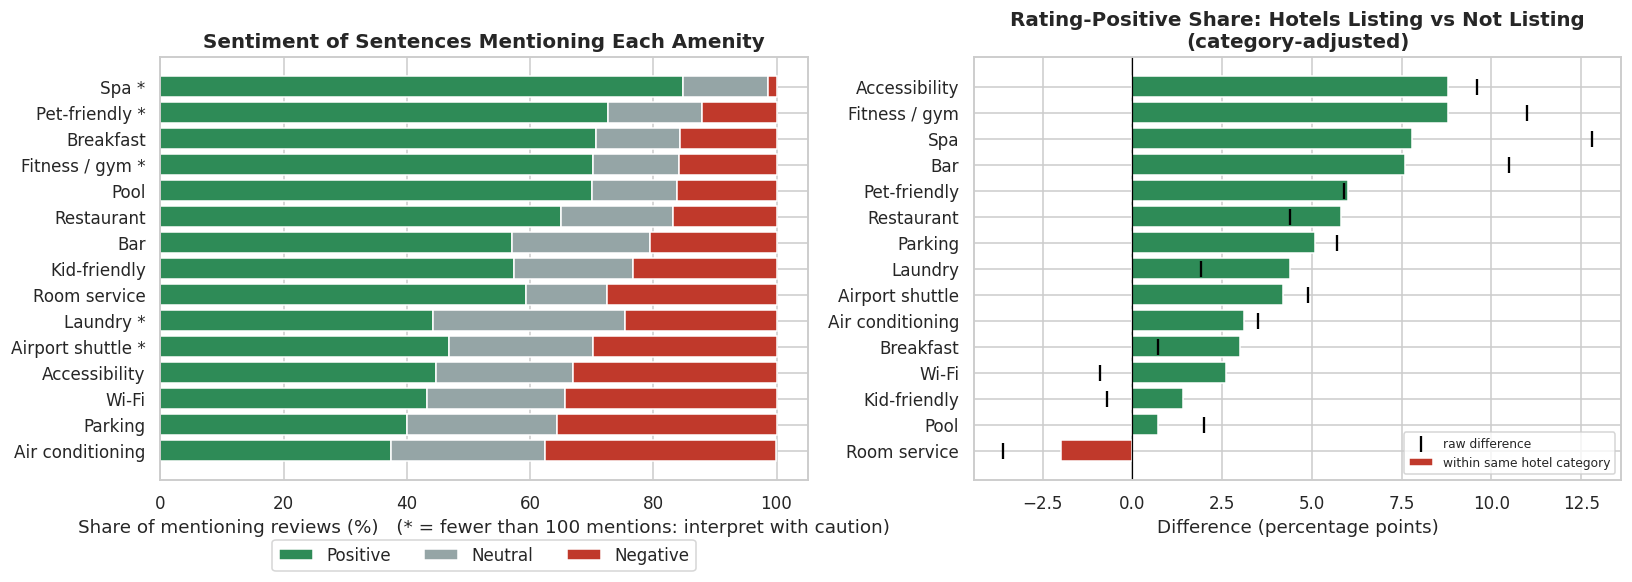

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
o = amen_sent.sort_values("Net (Pos% - Neg%)").assign(lbl=lambda d: np.where(d["Mentions"] < 100, d["Amenity"] + " *", d["Amenity"]))
left = np.zeros(len(o))
for s in ["Positive", "Neutral", "Negative"]:
    ax[0].barh(o["lbl"], o[f"{s} %"], left=left, color=SENT_COLORS[s], label=s); left += o[f"{s} %"].values
ax[0].set_title("Sentiment of Sentences Mentioning Each Amenity"); ax[0].set_xlabel("Share of mentioning reviews (%)   (* = fewer than 100 mentions: interpret with caution)")
ax[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
o2 = amen_list.sort_values("Diff same-category (pp)")
ax[1].barh(o2["Amenity"], o2["Diff same-category (pp)"], color=["#2e8b57" if v >= 0 else "#c0392b" for v in o2["Diff same-category (pp)"]], label="within same hotel category")
ax[1].scatter(o2["Diff (pp)"], o2["Amenity"], color="black", marker="|", s=120, zorder=3, label="raw difference"); ax[1].legend(loc="lower right", fontsize=8)
ax[1].axvline(0, color="black", lw=.8); ax[1].set_title("Rating-Positive Share: Hotels Listing vs Not Listing\n(category-adjusted)")
ax[1].set_xlabel("Difference (percentage points)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/amenity_sentiment.png", dpi=150, bbox_inches="tight"); plt.show()

In [34]:
amen_rel = amen_sent[amen_sent["Mentions"] >= 100]          # only amenities with an adequate sample are ranked
best_a = amen_rel.sort_values("Net (Pos% - Neg%)", ascending=False).iloc[0]; worst_a = amen_rel.sort_values("Net (Pos% - Neg%)").iloc[0]
small = amen_sent[amen_sent["Mentions"] < 100].sort_values("Net (Pos% - Neg%)", ascending=False)
small_txt = ", ".join(f"{r['Amenity']} (n={r['Mentions']}, net {r['Net (Pos% - Neg%)']:+.1f} pp, +/-{r['Positive % margin (+/- pp)']} pp)" for _, r in small.head(4).iterrows())
top_adj, low_adj = amen_list.iloc[0], amen_list.iloc[-1]

bf_t = theme_tbl[theme_tbl["Theme"] == "Breakfast"] if "theme_tbl" in globals() else pd.DataFrame()
bf_a = amen_sent[amen_sent["Amenity"] == "Breakfast"]
bf_note = ""
if len(bf_t) and len(bf_a):
    bf_note = (f"\n- **Why Breakfast shows two different positive percentages:** Section 19 reports **{bf_t.iloc[0]['% Positive']}%** because it labels the *whole review* "
               f"(VADER) of the {int(bf_t.iloc[0]['Total Mentions']):,} reviews that mention breakfast, whereas this table reports **{bf_a.iloc[0]['Positive %']}%** because it scores only "
               f"the *sentences that mention breakfast* ({int(bf_a.iloc[0]['Mentions']):,} reviews). The sentence-level view is stricter about the amenity itself; the whole-review view includes praise about other things in the same review. Both are valid, they answer different questions.")

display(Markdown(f"""**Interpretation (associations only).**
- Most-discussed amenities: {', '.join(amen_sent.head(4)['Amenity'] + ' (' + amen_sent.head(4)['Mentions'].astype(str) + ')')}.
- Among amenities with at least 100 mentions, sentences about **{best_a['Amenity']}** are the most positive in tone (net {best_a['Net (Pos% - Neg%)']:+.1f} pp, {best_a['Mentions']} mentions, +/-{best_a['Positive % margin (+/- pp)']} pp on the positive share); **{worst_a['Amenity']}** is the least positive (net {worst_a['Net (Pos% - Neg%)']:+.1f} pp, {worst_a['Mentions']} mentions).
- **Small samples (fewer than 100 mentions) are not ranked** because their percentages are unstable: {small_txt or 'none'}.
- Mentions are not evenly informative: when guests bring an amenity up it is often because something was missing or failed, so a low net score means *frequently mentioned alongside complaints*, not that the amenity causes dissatisfaction.
- Listing view (category-adjusted): reviews of hotels listing **{top_adj['Amenity']}** show the largest positive difference in rating-positive share ({top_adj['Diff same-category (pp)']:+.1f} pp within the same hotel category; raw {top_adj['Diff (pp)']:+.1f} pp) and **{low_adj['Amenity']}** the lowest ({low_adj['Diff same-category (pp)']:+.1f} pp; raw {low_adj['Diff (pp)']:+.1f} pp). Comparing inside categories reduces, but does not remove, confounding (city and price can still matter).{bf_note}"""))


**Interpretation (associations only).**
- Most-discussed amenities: Breakfast (1754), Air conditioning (954), Restaurant (803), Room service (542).
- Among amenities with at least 100 mentions, sentences about **Breakfast** are the most positive in tone (net +55.0 pp, 1754 mentions, +/-2.1 pp on the positive share); **Air conditioning** is the least positive (net +0.0 pp, 954 mentions).
- **Small samples (fewer than 100 mentions) are not ranked** because their percentages are unstable: Spa (n=73, net +83.5 pp, +/-8.2 pp), Pet-friendly (n=66, net +60.6 pp, +/-10.7 pp), Fitness / gym (n=57, net +54.4 pp, +/-11.9 pp), Laundry (n=61, net +19.7 pp, +/-12.5 pp).
- Mentions are not evenly informative: when guests bring an amenity up it is often because something was missing or failed, so a low net score means *frequently mentioned alongside complaints*, not that the amenity causes dissatisfaction.
- Listing view (category-adjusted): reviews of hotels listing **Fitness / gym** show the largest positive difference in rating-positive share (+8.8 pp within the same hotel category; raw +11.0 pp) and **Room service** the lowest (-2.0 pp; raw -3.6 pp). Comparing inside categories reduces, but does not remove, confounding (city and price can still matter).
- **Why Breakfast shows two different positive percentages:** Section 19 reports **79.3%** because it labels the *whole review* (VADER) of the 1,754 reviews that mention breakfast, whereas this table reports **70.7%** because it scores only the *sentences that mention breakfast* (1,754 reviews). The sentence-level view is stricter about the amenity itself; the whole-review view includes praise about other things in the same review. Both are valid, they answer different questions.

## Section 21 — Customer Pain-Point Analysis

Pain points are counted **inside negative reviews** (VADER = Negative) using specific complaint patterns (e.g. *dirty*, *rude*, *not working*, *slow*), so a neutral word such as "room" alone is not counted as a complaint. For corroboration we also count matches among **low-rated reviews (rating < 3)**. Only pain points with at least `MIN_PAIN` negative mentions are kept.

Negative (VADER) reviews: 4,869; low-rated reviews: 5,586. Pain points dropped (< 30 mentions): none


,Rank,Pain Point,Negative Mentions,% of negative reviews,Mentions in low-rated (<3) reviews,Example Review
0,1,Cleanliness / hygiene,1497,30.7,1665,"Worst hotel, very dirty room, food is also not good (Please check photos of food, they have charged 300 rs..."
1,2,Rude / unhelpful staff,992,20.4,1067,Except for that Thin short boy receptionist everything is good. But his rude and abusive behaviour is very...
2,3,Broken / poorly maintained,747,15.3,822,"Very worst experience in this stay, rooms are very very worst, toilets are having leakage and worst, beds ..."
3,4,Bathroom / hot-water issues,599,12.3,617,"Very very bad experience very bad rooms,beds are very very poor, floor tiles is very poor, bad toilets, ex..."
4,5,Price / value for money,576,11.8,637,I would rather not to give one star also but DONT EVER STAY HERE WORST EXPERIENCE EVER WASTE PEOPLE WASTE ...
5,6,Slow / poor service,570,11.7,602,Worst rooms and worst service. The staff keeps demanding money in cash only as they want to bypass the tax...
6,7,Bed / bedding discomfort,437,9.0,470,"Had a very bad experience staying at this place Not a genuine place at all Washrooms were very dirty, no l..."
7,8,Small / cramped rooms,361,7.4,431,One of the worst hotel in panjim small rooms an verry dirty room vibes is totally negative Staff is really...
8,9,Food / breakfast quality,345,7.1,359,One of the worst hotel in panjim Very very very small rooms Staff is really bad Dirty rooms Breakfast tast...
9,10,AC / cooling problems,299,6.1,320,Hotel location is good. But staff behavior is most terrible. Rooms are very much dirty as per money. Even ...


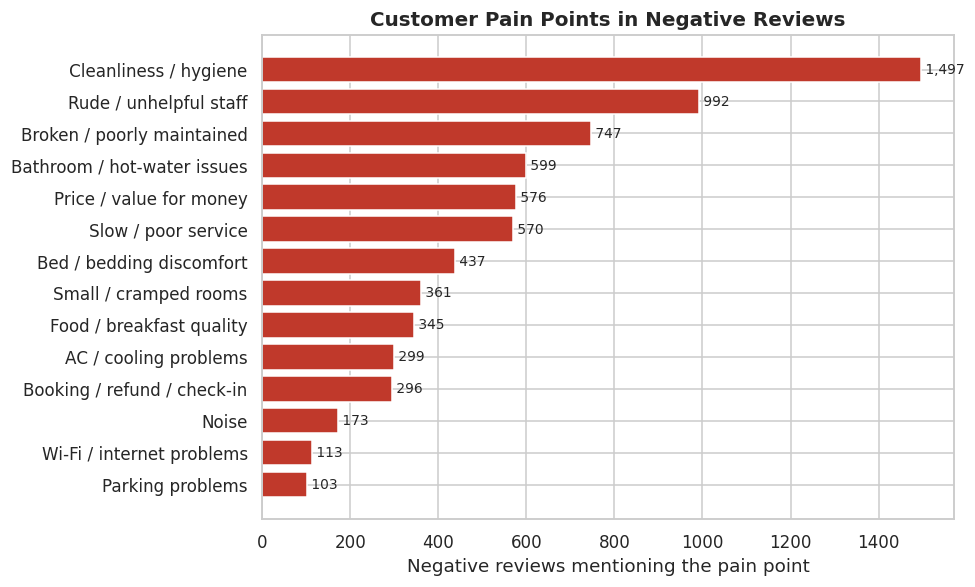

In [35]:
MIN_PAIN = 30
PAIN = {
 "Cleanliness / hygiene":       r"\bdirty\b|\bunclean\b|\bfilth\w*|\bnot (very |so |that |at all |too |properly )?(clean|hygien\w*)\b|\bunhygien\w*|\bstink\w*|\bsmell\w*|\bcockroach\w*|\bbed ?bugs?\b|\bstain\w*|\bmou?ld\b|\bdust\w*|\bno cleanliness\b|\bpoor (cleanliness|hygiene)\b",
 "Rude / unhelpful staff":      r"\brude\w*|\bimpolite\b|\bunprofessional\b|\bmisbehav\w*|\barrogan\w*|\bunhelpful\b|\bnot (very )?(helpful|cooperative|friendly|polite|responsive|supportive)\b|\bpoor (staff|behaviou?r|attitude)\b|\bbad (staff|behaviou?r|attitude)\b|\battitude\b",
 "Slow / poor service":         r"\bslow\w*|\bdelay\w*|\bwaited\b|\bwaiting\b|\btook (a )?(long|too long|forever|hours?)\b|\bpoor service\b|\bbad service\b|\bworst service\b|\bno service\b|\bno response\b|\bnot responding\b",
 "Broken / poorly maintained":  r"\bnot working\b|\bbroken\b|\bdamaged\b|\bpoor(ly)? maint\w*|\bnot maintained\b|\bleak\w*|\bworn\b|\bfaulty\b|\b(does|did|do)( not|n['’]?t) work\b|\bnot properly working\b|\bout of order\b",
 "AC / cooling problems":       r"\b(ac|a/c|aircon\w*|air[- ]?condition\w*)\b[^.]{0,40}\b(not|no|never|poor|bad|issue|problem|broken|noisy|leak\w*|worst)\b|\b(not|no|poor|bad)\b[^.]{0,20}\b(ac|a/c|cooling)\b",
 "Wi-Fi / internet problems":   r"\b(wi-?fi|wifi|internet|network)\b[^.]{0,40}\b(not|no|poor|bad|slow|weak|issue|problem|never|unavailable)\b|\b(no|poor|bad|slow|weak|not)\b[^.]{0,20}\b(wi-?fi|wifi|internet)\b",
 "Noise":                       r"\bnois\w+|\bloud\b|\bdisturb\w*",
 "Bathroom / hot-water issues":  r"\bno hot water\b|\bhot water\b[^.]{0,30}\b(not|no|never|issue|problem)\b|\b(bathrooms?|toilets?|washrooms?)\b[^.]{0,40}\b(dirty|smell\w*|small|broken|not|no|leak\w*|bad|poor|worst|unclean)\b",
 "Small / cramped rooms":       r"\bsmall\b|\btiny\b|\bcramped\b|\bcongested\b|\bnarrow\b|\bnot spacious\b|\bsuffocat\w*",
 "Food / breakfast quality":    r"\b(food|breakfast|dinner|lunch|meals?|buffet|tea|coffee)\b[^.]{0,40}\b(bad|poor|worst|not|cold|tasteless|stale|average|terrible|horrible|awful|disappoint\w*|limited)\b|\b(bad|poor|worst|tasteless|stale|terrible|horrible|awful)\b[^.]{0,20}\b(food|breakfast|dinner|lunch|meals?)\b",
 "Price / value for money":     r"\boverpriced\b|\bexpensive\b|\bcostly\b|\bover ?charg\w*|\bwaste of money\b|\bnot worth\b|\bhigh (price|rate|tariff|charges?)\b|\bextra (charge|money|cost)\w*|\brip ?off\b|\bhidden (charge|cost)\w*|\bcharged\b",
 "Booking / refund / check-in":  r"\brefund\w*|\bcancel\w*|\bdeposit\b|\breservation\b|\bcheck ?-?in\b[^.]{0,40}\b(late|delay\w*|problem|issue|refus\w*|denied|not|wait\w*)\b",
 "Parking problems":            r"\bparking\b[^.]{0,40}\b(not|no|problem|issue|difficult|limited|hard|bad)\b|\b(no|not|poor|limited)\b[^.]{0,20}\bparking\b",
 "Bed / bedding discomfort":    r"\b(beds?|mattress\w*|pillows?\w*|bed ?sheets?|blankets?|linen)\b[^.]{0,40}\b(dirty|hard|uncomfortable|stain\w*|smell\w*|bad|poor|old|torn|not|worst|bugs?)\b",
}

neg_rev = corpus[corpus["vader_sentiment"] == "Negative"]
low_rev = corpus[corpus["review_rating_5"] < 3]
pain_rows = []
used_examples = set()                       # make sure each pain point shows a different real review
for name, pat in PAIN.items():
    m_neg = neg_rev["text_lc"].str.contains(pat, regex=True)
    m_low = low_rev["text_lc"].str.contains(pat, regex=True)
    pool = neg_rev[m_neg & neg_rev["text_light"].str.len().between(60, 300) & ~neg_rev.index.isin(used_examples)].sort_values("vader_compound")
    if len(pool):
        used_examples.add(pool.index[0]); example = pool["text_light"].iloc[0]
    else:
        example = neg_rev[m_neg]["text_light"].iloc[0][:300] if m_neg.any() else ""
    pain_rows.append({"Pain Point": name, "Negative Mentions": int(m_neg.sum()),
                      "% of negative reviews": round(m_neg.mean()*100, 1), "Mentions in low-rated (<3) reviews": int(m_low.sum()),
                      "Example Review": example})
pain_tbl = pd.DataFrame(pain_rows)
dropped = pain_tbl.loc[pain_tbl["Negative Mentions"] < MIN_PAIN, "Pain Point"].tolist()
pain_tbl = pain_tbl[pain_tbl["Negative Mentions"] >= MIN_PAIN].sort_values("Negative Mentions", ascending=False).reset_index(drop=True)
pain_tbl.insert(0, "Rank", range(1, len(pain_tbl)+1))
print(f"Negative (VADER) reviews: {len(neg_rev):,}; low-rated reviews: {len(low_rev):,}. Pain points dropped (< {MIN_PAIN} mentions): {dropped or 'none'}")
display(pain_tbl)

fig, ax = plt.subplots(figsize=(9, 5.5))
p = pain_tbl.sort_values("Negative Mentions")
ax.barh(p["Pain Point"], p["Negative Mentions"], color=SENT_COLORS["Negative"])
for i, v in enumerate(p["Negative Mentions"]): ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title("Customer Pain Points in Negative Reviews"); ax.set_xlabel("Negative reviews mentioning the pain point")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pain_points.png", dpi=150); plt.show()

*Note.* One review can mention several pain points, so counts overlap and should not be added together. Keyword/regex patterns can miss paraphrases and can occasionally match a non-complaint; the example column lets you spot-check each pattern.

## Section 22 — Customer Experience Themes

Each theme from Section 19 is summarised with its evidence (how many reviews mention it), its sentiment, and the business meaning.

In [36]:
MEANING = {
 "Room": "Core product; room condition is mentioned in most stays and drives overall impression.",
 "Staff": "Staff behaviour is a controllable, training-driven part of experience.",
 "Service": "Responsiveness and speed of service shape satisfaction.",
 "Cleanliness": "Hygiene is a basic expectation; failures damage trust quickly.",
 "Food": "Dining quality is part of perceived value.",
 "Breakfast": "A visible amenity that guests evaluate explicitly.",
 "Location": "A fixed attribute; matters for positioning and marketing rather than operations.",
 "Wi-Fi": "A basic-expectation amenity; reliability matters more than availability.",
 "Parking": "Practical amenity, especially for drive-in guests.",
 "Bathroom": "Fittings and hot water are common maintenance touch-points.",
 "Bed / bedding": "Sleep comfort is central to the product.",
 "Price / value": "Guests judge price relative to what they received.",
 "Facilities": "General reference to what the hotel offers.",
 "Air conditioning": "Climate comfort is critical in Indian hotel stays.",
 "Noise": "Affects rest quality; usually a building/management issue.",
 "View": "A differentiator that guests tend to praise when present.",
}
net_overall = overall_pos - overall_neg
def sentiment_label(pos, neg):
    net = pos - neg
    return "Strongly positive" if net >= 60 else "Positive" if net >= 30 else "Mixed" if net >= 0 else "Negative-leaning"

exp = theme_tbl.copy()
exp["Evidence"] = exp["Total Mentions"].map("{:,}".format) + " reviews (" + exp["% of reviews mentioning"].astype(str) + "%)"
exp["Sentiment"] = [f"{sentiment_label(p, n)} ({p:.0f}% pos / {n:.0f}% neg)" for p, n in zip(exp["% Positive"], exp["% Negative"])]
exp["Business Meaning"] = exp["Theme"].map(MEANING)
theme_summary = exp[["Theme", "Evidence", "Sentiment", "Business Meaning"]]
display(theme_summary)
print(f"For reference, the whole corpus is {overall_pos:.0f}% positive / {overall_neg:.0f}% negative (net {net_overall:+.0f} pp). Only themes with >= {MIN_THEME} mentions are shown.")

,Theme,Evidence,Sentiment,Business Meaning
0,Room,"9,682 reviews (37.0%)",Positive (71% pos / 26% neg),Core product; room condition is mentioned in most stays and drives overall impression.
1,Staff,"8,506 reviews (32.5%)",Positive (78% pos / 21% neg),"Staff behaviour is a controllable, training-driven part of experience."
2,Service,"6,916 reviews (26.4%)",Positive (79% pos / 20% neg),Responsiveness and speed of service shape satisfaction.
3,Cleanliness,"6,621 reviews (25.3%)",Positive (74% pos / 25% neg),Hygiene is a basic expectation; failures damage trust quickly.
4,Location,"4,636 reviews (17.7%)",Strongly positive (85% pos / 12% neg),A fixed attribute; matters for positioning and marketing rather than operations.
5,Food,"3,923 reviews (15.0%)",Strongly positive (83% pos / 15% neg),Dining quality is part of perceived value.
6,Price / value,"3,565 reviews (13.6%)",Positive (66% pos / 30% neg),Guests judge price relative to what they received.
7,Bathroom,"1,996 reviews (7.6%)",Negative-leaning (45% pos / 52% neg),Fittings and hot water are common maintenance touch-points.
8,Breakfast,"1,754 reviews (6.7%)",Strongly positive (79% pos / 19% neg),A visible amenity that guests evaluate explicitly.
9,Bed / bedding,"1,360 reviews (5.2%)",Negative-leaning (42% pos / 56% neg),Sleep comfort is central to the product.


For reference, the whole corpus is 76% positive / 19% negative (net +58 pp). Only themes with >= 50 mentions are shown.


## Section 23 — Connect Text Mining to Review 1

Review 1 identified **which hotel characteristics and amenities are associated with hotel success** (price, review count, amenity count, free parking, free Wi-Fi, kid-friendly facilities, accessibility). Text mining now examines **what customers actually say about their experience**. The three strands combine into the integrated recommendations:

```
Hotel Characteristics ─► Hotel Success Analysis (Review 1: EDA + classification) ─┐
Customer Reviews      ─► Text Mining ─► Customer Sentiment & Pain Points (this notebook) ├─► Integrated Business Recommendations
Amenities             ─► Amenity Patterns (EDA, Apriori by teammate, amenity-sentiment here) ┘
```

The table below places Review 1's amenity signals next to the review-level evidence from this notebook. **They are different units** (Review 1: hotel-level success-rate difference in points from the Review 1 presentation; Review 2: review-level difference in the share of rating-positive reviews) so they are compared for *direction*, not magnitude.

In [37]:
# Values below are quoted from the Review 1 presentation (EDA slide, hotel-level success-rate difference, points)
REVIEW1 = {"Bar": 11.55, "Parking (free)": 9.10, "Accessibility": 8.25, "Wi-Fi (free)": 7.74, "Kid-friendly": -0.87, "Room service": -2.43}
R1_PATTERNS = {"Bar": r"\bbar\b", "Parking (free)": r"free parking", "Accessibility": r"accessible", "Wi-Fi (free)": r"free wi-?fi",
               "Kid-friendly": r"kid-friendly", "Room service": r"room service"}
rows = []
for k, pat in R1_PATTERNS.items():
    r = listing_effect(k, pat)
    ment = amen_sent[amen_sent["Amenity"] == {"Parking (free)":"Parking","Wi-Fi (free)":"Wi-Fi"}.get(k, k)]
    rows.append({"Amenity": k, "Review 1: success-rate diff (pts, hotel-level)": REVIEW1[k],
                 "Review 2: rating-positive diff (pp, review-level)": round(r["Diff (pp)"], 1) if r else np.nan,
                 "Review 2: net sentiment of mentions (pp)": ment["Net (Pos% - Neg%)"].iloc[0] if len(ment) else np.nan})
bridge = pd.DataFrame(rows); display(bridge)
agree = ((np.sign(bridge.iloc[:, 1]) == np.sign(bridge.iloc[:, 2])) & bridge.iloc[:, 2].notna()).sum()
print(f"Direction of the amenity difference agrees between Review 1 and the review-level view for {agree} of {bridge.iloc[:, 2].notna().sum()} comparable amenities.")

,Amenity,"Review 1: success-rate diff (pts, hotel-level)","Review 2: rating-positive diff (pp, review-level)",Review 2: net sentiment of mentions (pp)
0,Bar,11.55,10.5,36.5
1,Parking (free),9.10,11.2,4.5
2,Accessibility,8.25,9.6,11.8
3,Wi-Fi (free),7.74,8.5,8.9
4,Kid-friendly,-0.87,-0.7,34.0
5,Room service,-2.43,-3.6,31.9


Direction of the amenity difference agrees between Review 1 and the review-level view for 6 of 6 comparable amenities.


## Section 24 — Additional Pattern Analysis

Only analyses that answer a business question are included: *Do some hotel categories or cities attract more negative text? Does review length or rating level change how reliable text sentiment is?*

By hotel category:


,Reviews,Mean rating (5-pt),VADER Positive %,VADER Negative %,Rating-positive %
hotel_category_clean,,,,,
2-star hotel,2153,3.67,69.95,24.01,65.16
1-star hotel,347,3.74,70.61,22.19,67.72
3-star hotel,10370,3.83,73.66,21.49,69.86
Unknown,8569,4.07,76.81,17.41,76.26
4-star hotel,2937,4.18,82.02,14.23,79.09
5-star hotel,1799,4.49,88.22,7.56,87.38


By city:


,Reviews,Mean rating (5-pt),VADER Positive %,VADER Negative %,Rating-positive %
analysis_location,,,,,
Hyderabad,2244,3.67,69.43,24.55,65.37
Delhi,2599,3.75,70.64,23.51,67.22
Mumbai,2397,3.84,73.09,21.40,69.29
Kolkata,2391,3.88,74.07,19.95,71.27
Coimbatore,1301,3.91,75.48,19.52,72.10
Visakhapatnam,2392,3.99,75.71,19.52,74.04
Bengaluru,2281,3.96,75.41,19.42,73.43
Chennai,2747,4.05,78.16,16.93,76.16
Kochi,2413,4.06,79.53,15.54,76.30


By review source (>=100 reviews):


,Reviews,Mean rating (5-pt),VADER Positive %,VADER Negative %,Rating-positive %
review_source_clean,,,,,
Google,24710,3.95,75.70,19.25,72.91
freecancellations.com,178,4.43,66.29,12.36,85.39
Bluepillow,112,4.59,67.86,8.93,91.96
Tripadvisor,1070,4.62,93.64,5.42,90.93


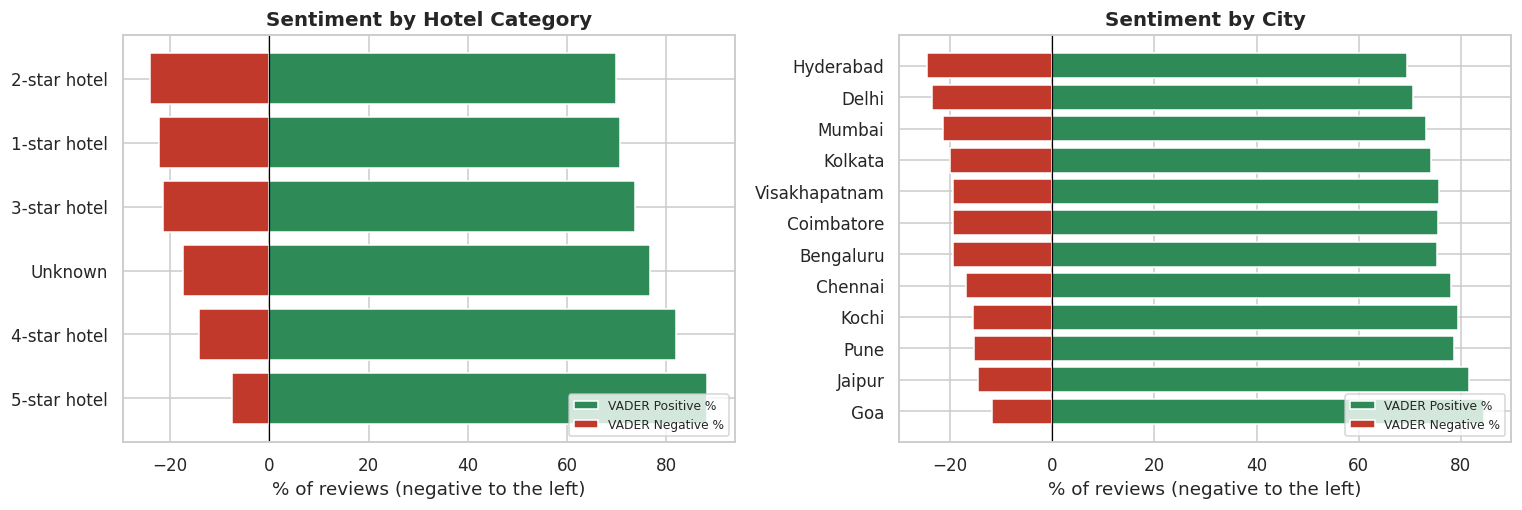

In [38]:
def sentiment_profile(group_col, min_reviews=100):
    g = corpus.groupby(group_col)
    t = pd.DataFrame({"Reviews": g.size(), "Mean rating (5-pt)": g["review_rating_5"].mean(),
                      "VADER Positive %": g["vader_pos"].mean()*100, "VADER Negative %": g["vader_neg"].mean()*100,
                      "Rating-positive %": g["rating_pos"].mean()*100})
    return t[t["Reviews"] >= min_reviews].round(2).sort_values("VADER Negative %", ascending=False)

cat_prof  = sentiment_profile(COL["category"]);  city_prof = sentiment_profile(COL["city"]); src_prof = sentiment_profile(COL["source"], 100)
print("By hotel category:"); display(cat_prof)
print("By city:"); display(city_prof)
print("By review source (>=100 reviews):"); display(src_prof)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, prof, ttl in [(ax[0], cat_prof, "Sentiment by Hotel Category"), (ax[1], city_prof, "Sentiment by City")]:
    p = prof.sort_values("VADER Negative %")
    a.barh(p.index.astype(str), p["VADER Positive %"], color=SENT_COLORS["Positive"], label="VADER Positive %")
    a.barh(p.index.astype(str), -p["VADER Negative %"], color=SENT_COLORS["Negative"], label="VADER Negative %")
    a.axvline(0, color="black", lw=.8); a.set_title(ttl); a.set_xlabel("% of reviews (negative to the left)"); a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sentiment_by_category_city.png", dpi=150); plt.show()

Agreement between VADER and rating-based sentiment by review length:


,Reviews,Agreement,Mean_abs_compound
length_bucket,,,
1-3 words,4414,84.7,0.430
4-10,6326,88.2,0.581
11-30,7466,89.8,0.731
31-80,5331,86.9,0.813
81+,2638,83.9,0.868


VADER mean compound by star rating:


,Reviews,Mean_compound,Agreement
star,,,
1,4706,-0.521,81.8
2,876,-0.147,56.2
3,1257,0.259,14.7
4,2731,0.598,89.1
5,16605,0.709,95.8


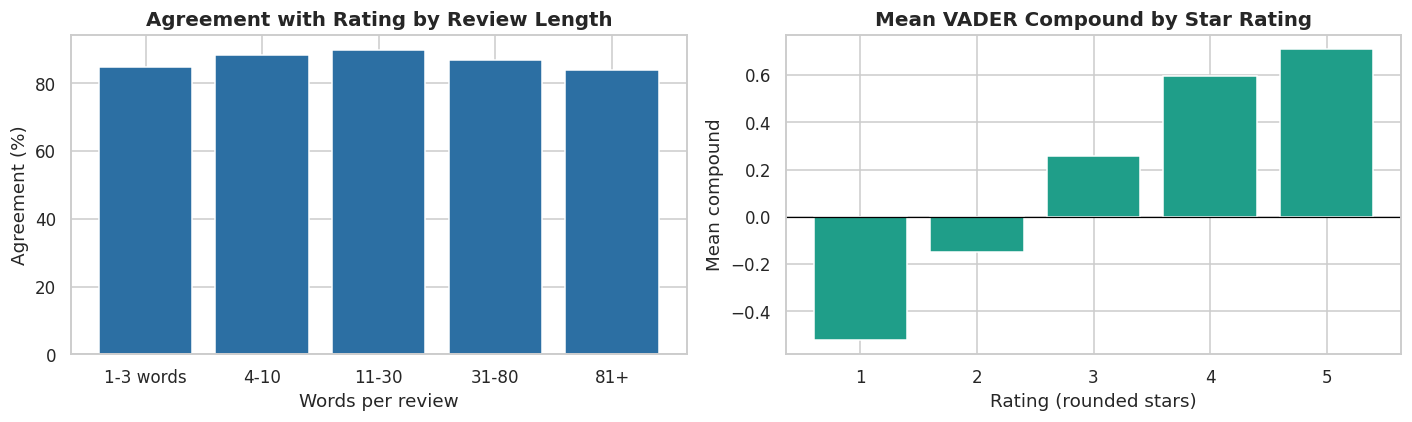

In [39]:
# Review length / rating level vs how well text sentiment agrees with the rating reference
bins = [0, 3, 10, 30, 80, np.inf]; labels = ["1-3 words", "4-10", "11-30", "31-80", "81+"]
corpus["length_bucket"] = pd.cut(corpus["word_count"], bins=bins, labels=labels)
corpus["agree"] = (corpus["rating_sentiment"] == corpus["vader_sentiment"]).astype(int)
len_prof = corpus.groupby("length_bucket", observed=True).agg(Reviews=("agree", "size"), Agreement=("agree", "mean"),
                                                              Mean_abs_compound=("vader_compound", lambda s: s.abs().mean())).round(3)
len_prof["Agreement"] = (len_prof["Agreement"]*100).round(1)
star = corpus.assign(star=corpus["review_rating_5"].round().clip(1, 5).astype(int)).groupby("star").agg(Reviews=("agree", "size"), Mean_compound=("vader_compound", "mean"), Agreement=("agree", "mean")).round(3)
star["Agreement"] = (star["Agreement"]*100).round(1)
print("Agreement between VADER and rating-based sentiment by review length:"); display(len_prof)
print("VADER mean compound by star rating:"); display(star)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(len_prof.index.astype(str), len_prof["Agreement"], color="#2c6fa3"); ax[0].set_title("Agreement with Rating by Review Length")
ax[0].set_ylabel("Agreement (%)"); ax[0].set_xlabel("Words per review")
ax[1].bar(star.index.astype(str), star["Mean_compound"], color="#1f9e89"); ax[1].axhline(0, color="black", lw=.8)
ax[1].set_title("Mean VADER Compound by Star Rating"); ax[1].set_xlabel("Rating (rounded stars)"); ax[1].set_ylabel("Mean compound")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/length_and_rating_effects.png", dpi=150); plt.show()

## Section 25 — Business Insights

Each insight follows **Finding → Evidence → Business implication**. Evidence is pulled from the tables above; implications are phrased as associations, not causes.

In [40]:
# ---------- Helpers to pull values from the result tables ----------
def theme_row(name):
    r = theme_tbl[theme_tbl["Theme"] == name]; return r.iloc[0] if len(r) else None
def pain_row(name):
    r = pain_tbl[pain_tbl["Pain Point"] == name]; return r.iloc[0] if len(r) else None

# Hotel-level view of text sentiment (>= 5 reviews) vs the hotel's overall rating, for the Review 1 link
hotel_sent = corpus.groupby(COL["hotel_id"]).agg(n_reviews=("vader_compound", "size"), mean_compound=("vader_compound", "mean"),
                                                  pct_vader_negative=("vader_neg", "mean"), pct_vader_positive=("vader_pos", "mean"),
                                                  mean_review_rating=("review_rating_5", "mean"))
hotel_sent["pct_vader_negative"] *= 100; hotel_sent["pct_vader_positive"] *= 100
hotel_sent = hotel_sent.join(df.groupby(COL["hotel_id"])["customer_rating"].first())
hs5 = hotel_sent[hotel_sent["n_reviews"] >= 5]
corr_hotel = hs5[["mean_compound", "customer_rating"]].corr(method="spearman").iloc[0, 1]
print(f"Hotels with >=5 reviews: {len(hs5):,}; Spearman(mean VADER compound, hotel customer_rating) = {corr_hotel:.3f}")

amen_big = amen_sent[amen_sent["Mentions"] >= 100]                       # avoid conclusions from tiny samples
best_am, worst_am = amen_big.sort_values("Net (Pos% - Neg%)").iloc[-1], amen_big.sort_values("Net (Pos% - Neg%)").iloc[0]
top_list = amen_list.iloc[0]
low_rated_not_neg = 100 - ct_pct.loc["Negative", "Negative"]
short_pct = (corpus["word_count"] <= 5).mean() * 100

def over(row, tol=2):   # is the theme clearly over-represented in negative reviews (more than tol pp above overall)?
    return row is not None and row["Neg vs overall (pp)"] > tol

insights = []
insights.append(("A. Customer Experience",
  "Guests are mostly positive in their own words, but a distinct negative minority exists.",
  f"VADER: {pos_p}% positive / {neu_p}% neutral / {neg_p}% negative; rating-based reference: {rs_tbl.loc['Positive','Percent']}% / {rs_tbl.loc['Neutral','Percent']}% / {rs_tbl.loc['Negative','Percent']}%.",
  "Track the share of negative reviews (not just the average rating); the negative minority is where concrete problems are described."))
cl, bt, bd, ac = theme_row("Cleanliness"), theme_row("Bathroom"), theme_row("Bed / bedding"), theme_row("Air conditioning")
cp = pain_row("Cleanliness / hygiene")
if cl is not None and cp is not None:
    insights.append(("D. Rooms / Cleanliness",
      f"Cleanliness/hygiene is the most frequent specific complaint, and bathroom, bedding and AC themes are over-represented in negative reviews.",
      f"{cp['Negative Mentions']:,} negative reviews ({cp['% of negative reviews']}%) contain a cleanliness complaint. Share of negative reviews among mentions: " +
      "; ".join(f"{r['Theme']} {r['% Negative']}%" for r in [bt, bd, ac] if r is not None) + f" (overall {overall_neg:.1f}%).",
      "Prioritise housekeeping standards and a maintenance checklist (bathroom fittings, hot water, bedding, AC) - areas where a failure is explicitly described."))
st, sv = theme_row("Staff"), theme_row("Service")
rp, sp = pain_row("Rude / unhelpful staff"), pain_row("Slow / poor service")
if st is not None and sv is not None:
    insights.append(("C. Service",
      "Staff and service are mentioned very often and mostly positively, yet staff behaviour and slow service are leading specific complaints.",
      f"Staff: {st['% Positive']}% positive / {st['% Negative']}% negative among {st['Total Mentions']:,} mentions; Service: {sv['% Positive']}% / {sv['% Negative']}% among {sv['Total Mentions']:,}." +
      (f" Negative reviews cite rude/unhelpful staff {rp['Negative Mentions']:,} times" if rp is not None else "") + (f" and slow/poor service {sp['Negative Mentions']:,} times." if sp is not None else "."),
      "Staff conduct and responsiveness are controllable: training and a complaint-response routine can protect a strength."))
insights.append(("B. Amenities",
  f"Amenity sentiment differs: {best_am['Amenity']} is discussed most positively and {worst_am['Amenity']} least positively (amenities with >=100 mentions; smaller samples are not ranked).",
  f"Net sentiment of sentences: {best_am['Amenity']} {best_am['Net (Pos% - Neg%)']:+.1f} pp ({best_am['Mentions']} mentions); {worst_am['Amenity']} {worst_am['Net (Pos% - Neg%)']:+.1f} pp ({worst_am['Mentions']} mentions). "
  f"Reviews of hotels listing {top_list['Amenity']} have a rating-positive share {top_list['Diff same-category (pp)']:+.1f} pp higher than hotels not listing it when compared within the same hotel category (raw difference {top_list['Diff (pp)']:+.1f} pp).",
  "Amenities associated with more positive text deserve priority in positioning; amenities that are frequently mentioned alongside complaints need reliability checks (association, not proven cause)."))
fd, bf = theme_row("Food"), theme_row("Breakfast")
if bf is not None:
    fp = pain_row("Food / breakfast quality")
    diffs = [r["Neg vs overall (pp)"] for r in [fd, bf] if r is not None]
    avg_diff = float(np.mean(diffs))
    if avg_diff > 2:   e_find, e_imp = "Food and breakfast show a higher-than-average negative share.", "Review menu and quality control."
    elif avg_diff < -2: e_find, e_imp = "Food and breakfast are mainly a strength (less negative than the corpus average).", "Maintain the current offer and monitor the minority complaints."
    else:              e_find, e_imp = "Food and breakfast are broadly in line with the corpus average and mostly positive.", "Maintain quality; monitor the minority complaints."
    insights.append(("E. Food / Breakfast", e_find,
      f"Whole-review sentiment of reviews mentioning breakfast ({bf['Total Mentions']:,}): {bf['% Positive']}% positive / {bf['% Negative']}% negative" + (f"; food: {fd['% Positive']}% / {fd['% Negative']}%" if fd is not None else "") +
      f" vs {overall_pos:.1f}% / {overall_neg:.1f}% overall" + (f"; {fp['Negative Mentions']:,} negative reviews describe a food/breakfast quality problem." if fp is not None else "."), e_imp))
pr = theme_row("Price / value"); pp = pain_row("Price / value for money")
if pr is not None:
    insights.append(("F. Value / Price",
      "Price and value-for-money comments are more negative than the corpus average." if over(pr) else "Price/value comments are not more negative than average.",
      f"{pr['Total Mentions']:,} reviews mention price/value: {pr['% Negative']}% negative vs {overall_neg:.1f}% overall." + (f" {pp['Negative Mentions']:,} negative reviews cite overpricing/charges." if pp is not None else ""),
      "Align price with visible quality and communicate charges clearly; value complaints often travel with room-quality complaints."))
insights.append(("G. Review Management",
  "Ratings alone hide reasons, and many reviews are very short.",
  f"{low_rated_not_neg:.1f}% of rating-negative reviews are not labelled negative by their text; {short_pct:.1f}% of reviews have <=5 words; hotel-level mean VADER compound vs customer_rating Spearman = {corr_hotel:.2f}.",
  "Combine rating and text signals, prompt guests for specifics, and respond to negative reviews that describe concrete problems."))

ins_df = pd.DataFrame(insights, columns=["Area", "Finding", "Evidence", "Business implication"]).sort_values("Area").reset_index(drop=True)
for _, r in ins_df.iterrows():
    display(Markdown(f"**{r['Area']}**\n\n- **Finding:** {r['Finding']}\n- **Evidence:** {r['Evidence']}\n- **Business implication:** {r['Business implication']}"))

Hotels with >=5 reviews: 1,588; Spearman(mean VADER compound, hotel customer_rating) = 0.640


**A. Customer Experience**

- **Finding:** Guests are mostly positive in their own words, but a distinct negative minority exists.
- **Evidence:** VADER: 76.3% positive / 5.1% neutral / 18.6% negative; rating-based reference: 73.8% / 4.9% / 21.3%.
- **Business implication:** Track the share of negative reviews (not just the average rating); the negative minority is where concrete problems are described.

**B. Amenities**

- **Finding:** Amenity sentiment differs: Breakfast is discussed most positively and Air conditioning least positively (amenities with >=100 mentions; smaller samples are not ranked).
- **Evidence:** Net sentiment of sentences: Breakfast +55.0 pp (1754 mentions); Air conditioning +0.0 pp (954 mentions). Reviews of hotels listing Fitness / gym have a rating-positive share +8.8 pp higher than hotels not listing it when compared within the same hotel category (raw difference +11.0 pp).
- **Business implication:** Amenities associated with more positive text deserve priority in positioning; amenities that are frequently mentioned alongside complaints need reliability checks (association, not proven cause).

**C. Service**

- **Finding:** Staff and service are mentioned very often and mostly positively, yet staff behaviour and slow service are leading specific complaints.
- **Evidence:** Staff: 77.9% positive / 20.8% negative among 8,506 mentions; Service: 79.0% / 19.6% among 6,916. Negative reviews cite rude/unhelpful staff 992 times and slow/poor service 570 times.
- **Business implication:** Staff conduct and responsiveness are controllable: training and a complaint-response routine can protect a strength.

**D. Rooms / Cleanliness**

- **Finding:** Cleanliness/hygiene is the most frequent specific complaint, and bathroom, bedding and AC themes are over-represented in negative reviews.
- **Evidence:** 1,497 negative reviews (30.7%) contain a cleanliness complaint. Share of negative reviews among mentions: Bathroom 52.0%; Bed / bedding 55.7%; Air conditioning 50.8% (overall 18.6%).
- **Business implication:** Prioritise housekeeping standards and a maintenance checklist (bathroom fittings, hot water, bedding, AC) - areas where a failure is explicitly described.

**E. Food / Breakfast**

- **Finding:** Food and breakfast are broadly in line with the corpus average and mostly positive.
- **Evidence:** Whole-review sentiment of reviews mentioning breakfast (1,754): 79.3% positive / 19.0% negative; food: 82.9% / 15.0% vs 76.3% / 18.6% overall; 345 negative reviews describe a food/breakfast quality problem.
- **Business implication:** Maintain quality; monitor the minority complaints.

**F. Value / Price**

- **Finding:** Price and value-for-money comments are more negative than the corpus average.
- **Evidence:** 3,565 reviews mention price/value: 29.9% negative vs 18.6% overall. 576 negative reviews cite overpricing/charges.
- **Business implication:** Align price with visible quality and communicate charges clearly; value complaints often travel with room-quality complaints.

**G. Review Management**

- **Finding:** Ratings alone hide reasons, and many reviews are very short.
- **Evidence:** 22.3% of rating-negative reviews are not labelled negative by their text; 25.2% of reviews have <=5 words; hotel-level mean VADER compound vs customer_rating Spearman = 0.64.
- **Business implication:** Combine rating and text signals, prompt guests for specifics, and respond to negative reviews that describe concrete problems.

## Section 26 — Business Recommendations

Each recommendation is generated from a result above. If a result were missing for a data set, that recommendation would be skipped automatically.

In [41]:
recs = []
if cp is not None:
    recs.append(f"**Fix hygiene first.** Cleanliness/hygiene is the most frequent complaint ({cp['Negative Mentions']:,} negative reviews, {cp['% of negative reviews']}%). Introduce daily room/bathroom inspection checklists and follow up on any review that mentions dirt, smell or pests.")
hard = [r for r in [bt, bd, ac] if r is not None and over(r)]
if hard:
    recs.append("**Run preventive maintenance on bathrooms, bedding and AC.** " + "; ".join(f"{r['Theme']} reviews are {r['% Negative']}% negative" for r in hard) + f" versus {overall_neg:.1f}% overall - these are fixable equipment/linen issues.")
if rp is not None or sp is not None:
    recs.append("**Invest in staff conduct and responsiveness.** " + (f"Rude/unhelpful staff appears in {rp['Negative Mentions']:,} negative reviews" if rp is not None else "") + (f" and slow/poor service in {sp['Negative Mentions']:,}" if sp is not None else "") + ". Add service-recovery training and a response-time target for complaints.")
recs.append(f"**Prioritise and quality-check amenities.** {top_list['Amenity']} and similar amenities are associated with a higher rating-positive share ({top_list['Diff same-category (pp)']:+.1f} pp within the same hotel category, raw {top_list['Diff (pp)']:+.1f} pp); amenities such as {worst_am['Amenity']} are often mentioned in complaints (net {worst_am['Net (Pos% - Neg%)']:+.1f} pp), so guarantee they work reliably rather than just listing them.")
recs.append(f"**Use review sentiment as an early-warning indicator.** VADER's compound score separates 1-2 star from 4-5 star reviews well (ROC-AUC {auc:.2f}); alert managers when a hotel's share of negative reviews rises, and monitor the top pain-point counts monthly.")
recs.append(f"**Combine text sentiment with the hotel-success model.** Hotel-level mean sentiment is positively related to the hotel's rating (Spearman {corr_hotel:.2f}). Because success was defined from rating, use sentiment and pain points as *diagnostic* features beside Review 1's predictors, validated on a proper train/test split, rather than as extra predictors of the same label.")
gap = cat_prof["VADER Negative %"]
recs.append(f"**Benchmark within hotel category.** Negative-text share ranges from {gap.min():.1f}% ({gap.idxmin()}) to {gap.max():.1f}% ({gap.idxmax()}); compare a hotel with peers of the same category rather than the overall average.")
recs.append(f"**Collect richer feedback.** {short_pct:.1f}% of reviews are 5 words or fewer and neutral (3-star) reviews are hardest to interpret (VADER F1 {per_cls.loc['Neutral','f1-score']:.2f}); use short guided prompts (e.g. room, staff, value) to capture usable detail.")
for i, r in enumerate(recs, 1):
    display(Markdown(f"{i}. {r}"))

1. **Fix hygiene first.** Cleanliness/hygiene is the most frequent complaint (1,497 negative reviews, 30.7%). Introduce daily room/bathroom inspection checklists and follow up on any review that mentions dirt, smell or pests.

2. **Run preventive maintenance on bathrooms, bedding and AC.** Bathroom reviews are 52.0% negative; Bed / bedding reviews are 55.7% negative; Air conditioning reviews are 50.8% negative versus 18.6% overall - these are fixable equipment/linen issues.

3. **Invest in staff conduct and responsiveness.** Rude/unhelpful staff appears in 992 negative reviews and slow/poor service in 570. Add service-recovery training and a response-time target for complaints.

4. **Prioritise and quality-check amenities.** Fitness / gym and similar amenities are associated with a higher rating-positive share (+8.8 pp within the same hotel category, raw +11.0 pp); amenities such as Air conditioning are often mentioned in complaints (net +0.0 pp), so guarantee they work reliably rather than just listing them.

5. **Use review sentiment as an early-warning indicator.** VADER's compound score separates 1-2 star from 4-5 star reviews well (ROC-AUC 0.95); alert managers when a hotel's share of negative reviews rises, and monitor the top pain-point counts monthly.

6. **Combine text sentiment with the hotel-success model.** Hotel-level mean sentiment is positively related to the hotel's rating (Spearman 0.64). Because success was defined from rating, use sentiment and pain points as *diagnostic* features beside Review 1's predictors, validated on a proper train/test split, rather than as extra predictors of the same label.

7. **Benchmark within hotel category.** Negative-text share ranges from 7.6% (5-star hotel) to 24.0% (2-star hotel); compare a hotel with peers of the same category rather than the overall average.

8. **Collect richer feedback.** 25.2% of reviews are 5 words or fewer and neutral (3-star) reviews are hardest to interpret (VADER F1 0.14); use short guided prompts (e.g. room, staff, value) to capture usable detail.

## Section 27 — Limitations

In [42]:
n_translated = int(df[COL["text_clean"]].astype(str).str.contains("Translated by Google").sum())
google_share = (corpus[COL["source"]] == "Google").mean() * 100
display(Markdown(f"""- **VADER is lexicon-based.** It scores words from a general-purpose dictionary and cannot reliably handle sarcasm, context or hotel-specific language; agreement with ratings was {acc*100:.1f}% overall and only {per_cls.loc['Neutral','f1-score']:.2f} F1 for the Neutral class.
- **Rating-based sentiment is a reference label, not absolute truth.** Ratings and text can disagree, so the metrics measure agreement with ratings.
- **Short reviews.** {short_pct:.1f}% of reviews have 5 words or fewer, which gives little text signal.
- **Missing and excluded reviews.** {int((~has_text).sum()):,} records ({(~has_text).mean()*100:.1f}%) have no review text; {len(excl):,} text records were excluded as emoji-only/non-English; {int(long_dup.sum()):,} long same-hotel duplicates were removed.
- **Language.** {n_translated:,} reviews contained a machine translation block (the English translation was analysed, which may differ from the original meaning). Non-English text written in Latin letters (e.g. Hinglish, German) is not detected and is scored by an English lexicon.
- **Source mix.** {google_share:.1f}% of analysed reviews come from Google, so findings mostly reflect Google reviewers; other sources are small (Section 24).
- **Synthetic data.** Review 1 added synthetic *hotel-level* records for modelling. This file contains no synthetic flag column and is the review-level collection (29,987 rows), so synthetic hotels do not enter the text mining; findings reflect real reviews only.
- **Associations, not causation.** Amenity/theme differences may reflect hotel category, city or price. Keyword and regex matching does not understand context and can miss paraphrases or over-match.
- **Time.** `review_date` holds relative strings (e.g. "a month ago"), so no time trend is analysed."""))

- **VADER is lexicon-based.** It scores words from a general-purpose dictionary and cannot reliably handle sarcasm, context or hotel-specific language; agreement with ratings was 87.4% overall and only 0.14 F1 for the Neutral class.
- **Rating-based sentiment is a reference label, not absolute truth.** Ratings and text can disagree, so the metrics measure agreement with ratings.
- **Short reviews.** 25.2% of reviews have 5 words or fewer, which gives little text signal.
- **Missing and excluded reviews.** 3,706 records (12.4%) have no review text; 67 text records were excluded as emoji-only/non-English; 39 long same-hotel duplicates were removed.
- **Language.** 870 reviews contained a machine translation block (the English translation was analysed, which may differ from the original meaning). Non-English text written in Latin letters (e.g. Hinglish, German) is not detected and is scored by an English lexicon.
- **Source mix.** 94.4% of analysed reviews come from Google, so findings mostly reflect Google reviewers; other sources are small (Section 24).
- **Synthetic data.** Review 1 added synthetic *hotel-level* records for modelling. This file contains no synthetic flag column and is the review-level collection (29,987 rows), so synthetic hotels do not enter the text mining; findings reflect real reviews only.
- **Associations, not causation.** Amenity/theme differences may reflect hotel category, city or price. Keyword and regex matching does not understand context and can miss paraphrases or over-match.
- **Time.** `review_date` holds relative strings (e.g. "a month ago"), so no time trend is analysed.

## Section 28 — Final Text Mining Conclusion

In [43]:
top_words_txt = ", ".join(w for w, _ in word_freq.most_common(8))
display(Markdown(f"""**Text mining extended the hotel analytics framework from hotel-level success prediction to customer-experience understanding.**

- **Major review themes:** the most frequent words are {top_words_txt}; the most frequent themes are {', '.join(theme_tbl.head(5)['Theme'])}.
- **Sentiment distribution:** {pos_p}% positive, {neu_p}% neutral, {neg_p}% negative by VADER (rating reference: {rs_tbl.loc['Positive','Percent']}% / {rs_tbl.loc['Neutral','Percent']}% / {rs_tbl.loc['Negative','Percent']}%).
- **Evaluation:** accuracy {acc*100:.1f}% (majority baseline {majority_acc*100:.1f}%), macro-F1 {mf1:.3f}, weighted-F1 {wf1:.3f}, kappa {kappa:.2f}; Positive and Negative are detected well, Neutral poorly.
- **Major pain points:** {', '.join(pain_tbl.head(4)['Pain Point'])}.
- **Important amenities:** {best_am['Amenity']} is discussed most positively and {worst_am['Amenity']} least positively; hotels listing {top_list['Amenity']} show the highest rating-positive difference.
- **Business value:** the pain-point and amenity evidence converts review text into specific operational priorities that complement Review 1's hotel-level findings."""))

**Text mining extended the hotel analytics framework from hotel-level success prediction to customer-experience understanding.**

- **Major review themes:** the most frequent words are room, good, stay, hotel, not, staff, service, experience; the most frequent themes are Room, Staff, Service, Cleanliness, Location.
- **Sentiment distribution:** 76.3% positive, 5.1% neutral, 18.6% negative by VADER (rating reference: 73.8% / 4.9% / 21.3%).
- **Evaluation:** accuracy 87.4% (majority baseline 73.8%), macro-F1 0.636, weighted-F1 0.873, kappa 0.68; Positive and Negative are detected well, Neutral poorly.
- **Major pain points:** Cleanliness / hygiene, Rude / unhelpful staff, Broken / poorly maintained, Bathroom / hot-water issues.
- **Important amenities:** Breakfast is discussed most positively and Air conditioning least positively; hotels listing Fitness / gym show the highest rating-positive difference.
- **Business value:** the pain-point and amenity evidence converts review text into specific operational priorities that complement Review 1's hotel-level findings.

# Presentation-Ready Results

## Section 29 — Exact values for the Review 2 presentation

All values below are produced by code from the CSV (nothing typed by hand). The same results are saved as CSV/JSON/PNG files in `text_mining_outputs/` for the dashboard and presentation team.

In [44]:
THEME_MIN_PRES = 500                                   # rule for ranking themes in the presentation list
big = theme_tbl[theme_tbl["Total Mentions"] >= THEME_MIN_PRES]
top_pos_themes = big.sort_values("% Positive", ascending=False).head(5)[["Theme", "Total Mentions", "% Positive"]]
top_neg_themes = big.sort_values("% Negative", ascending=False).head(5)[["Theme", "Total Mentions", "% Negative"]]

R = {
 "dataset": {"total_records": len(df), "total_columns": N_COLS_ORIG, "reviews_with_text": int(has_text.sum()),
             "missing_review_text": int((~has_text).sum()), "unique_review_texts": int(df.loc[has_text, COL["text_clean"]].nunique()),
             "hotels_with_text": int(df.loc[has_text, COL["hotel_id"]].nunique()), "final_corpus_reviews": len(corpus),
             "final_corpus_hotels": int(corpus[COL["hotel_id"]].nunique()), "mean_words": round(corpus["word_count"].mean(), 1),
             "median_words": float(corpus["word_count"].median()), "total_tokens": len(all_tokens), "vocabulary": len(word_freq)},
 "top10_words": [(w, c) for w, c in word_freq.most_common() if w not in FILLER][:10],
 "top_bigrams": [(" ".join(k), v) for k, v in bi_freq.most_common(5)],
 "top_pos_themes": top_pos_themes, "top_neg_themes": top_neg_themes,
 "vader_pct": v_pct.to_dict(), "rating_pct": rs_tbl["Percent"].to_dict(),
 "metrics": {"accuracy": acc, "macro_precision": mp, "macro_recall": mr, "macro_f1": mf1, "weighted_f1": wf1, "kappa": kappa,
             "majority_baseline": majority_acc, "roc_auc_clear": auc, "spearman": rho},
 "per_class_f1": per_cls["f1-score"].to_dict(), "binary_clear_signal": bin_metrics,
 "pain_points": pain_tbl.head(5)[["Pain Point", "Negative Mentions", "% of negative reviews"]],
 "best_amenity": best_am, "worst_amenity": worst_am, "top_listing_amenity": top_list,
 "insights": ins_df, "recs": recs,
}
display(Markdown("### 1-2. Dataset statistics and usable reviews")); display(pd.Series(R["dataset"], name="value").to_frame())
display(Markdown("### 3. Top 10 words")); display(pd.DataFrame(R["top10_words"], columns=["Word", "Frequency"]).T)
display(Markdown("### 4. Top 5 positive themes (themes with >= 500 mentions, ranked by % positive reviews)")); display(R["top_pos_themes"])
display(Markdown("### 5. Top 5 negative themes (themes with >= 500 mentions, ranked by % negative reviews)")); display(R["top_neg_themes"])
display(Markdown("### 6. Sentiment percentages")); display(pd.DataFrame({"VADER %": R["vader_pct"], "Rating-based %": R["rating_pct"]}))
display(Markdown("### 7-10. Evaluation of VADER vs rating-based reference")); display(pd.Series(R["metrics"], name="value").round(4).to_frame())
display(Markdown("### 7b. Clear-signal evaluation (Positive vs Negative only, 3-star excluded)")); display(pd.DataFrame(R["binary_clear_signal"]).T.round(4))
display(Markdown("### 11. Most important customer pain points")); display(R["pain_points"])
display(Markdown("### 12. Most positively / negatively discussed amenities (>= 100 mentions)"))
display(pd.concat([amen_big.sort_values("Net (Pos% - Neg%)", ascending=False).head(3).assign(Group="Most positive"),
                  amen_big.sort_values("Net (Pos% - Neg%)").head(3).assign(Group="Least positive")]))
display(Markdown("### 13. Key business insights (5)"))
KEY5 = ["D. Rooms / Cleanliness", "C. Service", "B. Amenities", "A. Customer Experience", "G. Review Management"]
key_insights = ins_df.set_index("Area").reindex([k for k in KEY5 if k in set(ins_df["Area"])]).reset_index()
for _, r in key_insights.iterrows(): display(Markdown(f"- **{r['Area']}** - {r['Finding']} *Evidence:* {r['Evidence']}"))
display(Markdown("### 14. Key recommendations (5)"))
for i, r in enumerate(R["recs"][:5], 1): display(Markdown(f"{i}. {r}"))

### 1-2. Dataset statistics and usable reviews

,value
total_records,29987.0
total_columns,42.0
reviews_with_text,26281.0
missing_review_text,3706.0
unique_review_texts,23557.0
hotels_with_text,1659.0
final_corpus_reviews,26175.0
final_corpus_hotels,1659.0
mean_words,32.4
median_words,15.0


### 3. Top 10 words

,0,1,2,3,4,5,6,7,8,9
Word,room,good,stay,hotel,not,staff,service,experience,clean,place
Frequency,14400,13450,12159,11205,10135,8306,8228,5839,5268,4027


### 4. Top 5 positive themes (themes with >= 500 mentions, ranked by % positive reviews)

...

1. **Fix hygiene first.** Cleanliness/hygiene is the most frequent complaint (1,497 negative reviews, 30.7%). Introduce daily room/bathroom inspection checklists and follow up on any review that mentions dirt, smell or pests.

2. **Run preventive maintenance on bathrooms, bedding and AC.** Bathroom reviews are 52.0% negative; Bed / bedding reviews are 55.7% negative; Air conditioning reviews are 50.8% negative versus 18.6% overall - these are fixable equipment/linen issues.

3. **Invest in staff conduct and responsiveness.** Rude/unhelpful staff appears in 992 negative reviews and slow/poor service in 570. Add service-recovery training and a response-time target for complaints.

4. **Prioritise and quality-check amenities.** Fitness / gym and similar amenities are associated with a higher rating-positive share (+8.8 pp within the same hotel category, raw +11.0 pp); amenities such as Air conditioning are often mentioned in complaints (net +0.0 pp), so guarantee they work reliably rather than just listing them.

5. **Use review sentiment as an early-warning indicator.** VADER's compound score separates 1-2 star from 4-5 star reviews well (ROC-AUC 0.95); alert managers when a hotel's share of negative reviews rises, and monitor the top pain-point counts monthly.

In [45]:
# ---------- Save outputs for the dashboard / presentation team ----------
word_freq_df = pd.DataFrame(word_freq.most_common(100), columns=["word", "frequency"])
word_freq_df.to_csv(f"{OUT_DIR}/word_frequency_top100.csv", index=False)
pd.DataFrame([(" ".join(k), v) for k, v in bi_freq.most_common(50)], columns=["bigram", "frequency"]).to_csv(f"{OUT_DIR}/bigrams_top50.csv", index=False)
pd.DataFrame([(" ".join(k), v) for k, v in tri_freq.most_common(50)], columns=["trigram", "frequency"]).to_csv(f"{OUT_DIR}/trigrams_top50.csv", index=False)
pd.DataFrame({"vader_count": v_counts, "vader_pct": v_pct, "rating_count": rs_counts, "rating_pct": rs_tbl["Percent"]}).to_csv(f"{OUT_DIR}/sentiment_distribution.csv")
metrics.to_csv(f"{OUT_DIR}/sentiment_evaluation_metrics.csv", index=False); cm_df.to_csv(f"{OUT_DIR}/confusion_matrix.csv"); rep_df.to_csv(f"{OUT_DIR}/classification_report.csv")
theme_tbl.to_csv(f"{OUT_DIR}/theme_sentiment.csv", index=False); amen_sent.to_csv(f"{OUT_DIR}/amenity_mention_sentiment.csv", index=False)
amen_list.to_csv(f"{OUT_DIR}/amenity_listing_comparison.csv", index=False); pain_tbl.to_csv(f"{OUT_DIR}/pain_points.csv", index=False)
cat_prof.to_csv(f"{OUT_DIR}/sentiment_by_category.csv"); city_prof.to_csv(f"{OUT_DIR}/sentiment_by_city.csv")
ins_df.to_csv(f"{OUT_DIR}/business_insights.csv", index=False); pd.Series(recs, name="recommendation").to_csv(f"{OUT_DIR}/recommendations.csv", index=False)

review_cols = [COL["hotel_id"], COL["hotel_name"], COL["city"], COL["category"], COL["source"], "review_rating_5", "rating_sentiment",
               "vader_compound", "vader_sentiment", "word_count", "text_light"]
corpus[review_cols].to_csv(f"{OUT_DIR}/review_level_sentiment.csv", index=False)           # one row per analysed review
hotel_sent.reset_index().to_csv(f"{OUT_DIR}/hotel_level_text_sentiment.csv", index=False)  # one row per hotel (for the dashboard / Review 1 link)

summary_json = {k: (v if not isinstance(v, (pd.DataFrame, pd.Series)) else v.to_dict()) for k, v in R.items() if k not in ("best_amenity", "worst_amenity", "top_listing_amenity")}
with open(f"{OUT_DIR}/presentation_numbers.json", "w") as f:
    json.dump(summary_json, f, indent=2, default=str)

with zipfile.ZipFile("text_mining_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(OUT_DIR)): z.write(os.path.join(OUT_DIR, fn), fn)
print("Saved", len(os.listdir(OUT_DIR)), "files to", OUT_DIR, "and text_mining_outputs.zip")
try:                                                            # auto-download in Colab (ignored elsewhere)
    from google.colab import files as _f; _f.download("text_mining_outputs.zip")
except Exception:
    pass

Saved 36 files to text_mining_outputs and text_mining_outputs.zip


## Section 30 — Review 2 Presentation Slide Content

Generated from the computed results. Copy the bullets; insert the named chart (saved in `text_mining_outputs/`).

In [46]:
def slide(n, title, bullets, visual, numbers, takeaway):
    b = "\n".join(f"- {x}" for x in bullets)
    return f"""#### SLIDE {n}: {title}
{b}

**Visual to insert:** {visual}
**Exact numbers:** {numbers}
**Key takeaway:** {takeaway}
"""

D = R["dataset"]; M = R["metrics"]
neg_conf = per_cls["f1-score"]
S = []
S.append(slide(1, "Text Mining of Hotel Reviews",
  ["Team 5 - Integrated Hotel Analytics for Hotel Success, Amenities & Customer Experience",
   "Method 1 (Review 2): Text Mining - Durgam Poojitha (CB.SC.U4CSE23320)",
   "Review 1 asked: what characteristics are associated with hotel success?",
   "Review 2 asks: what are customers actually saying?"],
  "Title slide (no chart)", f"{D['final_corpus_reviews']:,} reviews analysed from {D['final_corpus_hotels']:,} hotels",
  "Text mining moves the project from hotel characteristics to customer voice."))
S.append(slide(2, "Text Mining Objective & Data",
  ["Data: all_india_hotel_cleaned.csv (review-level)",
   f"{D['total_records']:,} records; {D['reviews_with_text']:,} with review text ({D['missing_review_text']:,} without)",
   f"{D['unique_review_texts']:,} unique texts; {D['hotels_with_text']:,} hotels with text",
   f"Final corpus after cleaning: {D['final_corpus_reviews']:,} reviews",
   f"Average {D['mean_words']} words, median {D['median_words']:.0f} words per review"],
  "Corpus attrition table (Section 5) + review_length.png", f"funnel: {', '.join(str(x) for x in funnel['Records'])}",
  "A large, review-level corpus supports reliable text patterns."))
S.append(slide(3, "Text Preprocessing Pipeline",
  ["Handled missing reviews; kept English translation of 'Translated by Google' reviews",
   "Lowercase, removed URLs, HTML, punctuation, numbers, extra spaces",
   "Tokenised; removed stop-words but kept not/no/never/nor/neither",
   "Lemmatised (WordNet); removed very short tokens",
   "Two text versions: text_light (for VADER) and text_processed (for counts)"],
  "Before/after table (Section 5)", f"{D['total_tokens']:,} tokens; vocabulary {D['vocabulary']:,} words",
  "Negation-aware cleaning keeps the meaning that sentiment depends on."))
S.append(slide(4, "Word Frequency + Word Cloud",
  [f"Top words: {', '.join(w for w, _ in R['top10_words'][:8])}",
   f"Top bigrams: {', '.join(b for b, _ in R['top_bigrams'][:4])}",
   "Phrases keep context (e.g. 'not clean' vs 'clean')",
   "Word cloud = visual summary; frequency chart gives exact counts"],
  "top20_words.png and word_cloud.png", "; ".join(f"{w} {c:,}" for w, c in R["top10_words"]),
  "Reviews centre on room, staff, service, cleanliness and overall experience."))
S.append(slide(5, "Sentiment Analysis",
  ["VADER lexicon-based sentiment on each review (compound >= 0.05 positive, <= -0.05 negative)",
   f"VADER: {R['vader_pct']['Positive']}% positive, {R['vader_pct']['Neutral']}% neutral, {R['vader_pct']['Negative']}% negative",
   f"Rating-based reference: {R['rating_pct']['Positive']}% / {R['rating_pct']['Neutral']}% / {R['rating_pct']['Negative']}%",
   "Rating label (<3 negative, 3-<4 neutral, >=4 positive) is a reference, not absolute truth"],
  "vader_sentiment_distribution.png + rating_sentiment_distribution.png", f"Positive {R['vader_pct']['Positive']}%, Neutral {R['vader_pct']['Neutral']}%, Negative {R['vader_pct']['Negative']}%",
  "Overall guest sentiment is strongly positive, with a clear negative minority."))
S.append(slide(6, "Sentiment Evaluation + Confusion Matrix",
  [f"Accuracy {M['accuracy']*100:.1f}% (majority baseline {M['majority_baseline']*100:.1f}%)",
   f"Macro precision {M['macro_precision']:.3f}, macro recall {M['macro_recall']:.3f}, macro-F1 {M['macro_f1']:.3f}, weighted-F1 {M['weighted_f1']:.3f}",
   f"F1 by class: Positive {neg_conf['Positive']:.2f}, Negative {neg_conf['Negative']:.2f}, Neutral {neg_conf['Neutral']:.2f}",
   f"ROC-AUC for 1-2 vs 4-5 star reviews: {M['roc_auc_clear']:.2f}; kappa {M['kappa']:.2f}",
   f"Clear-signal reviews only (1-2 vs 4-5 stars): accuracy {R['binary_clear_signal']['forced_binary']['accuracy']*100:.1f}%, macro-F1 {R['binary_clear_signal']['forced_binary']['macro_f1']:.3f}"],
  "confusion_matrix.png + rating_vs_vader_heatmap.png", f"Accuracy {M['accuracy']:.4f}; macro-F1 {M['macro_f1']:.4f}",
  "Text sentiment agrees well with ratings for positive/negative reviews; neutral (3-star) reviews are hardest."))
S.append(slide(7, "Positive vs Negative Review Patterns",
  [f"Positive words: {', '.join(w for w, _ in pos_words.most_common(6))}",
   f"Negative words: {', '.join(w for w, _ in neg_words.most_common(6))}",
   f"Positive phrases: {', '.join(' '.join(k) for k, _ in pos_bi.most_common(3))}",
   f"Negative phrases: {', '.join(' '.join(k) for k, _ in neg_bi.most_common(3))}",
   "Most positive themes: " + ", ".join(R["top_pos_themes"]["Theme"].head(3)) + "; most negative: " + ", ".join(R["top_neg_themes"]["Theme"].head(3))],
  "top20_positive_words.png + top20_negative_words.png + theme_sentiment.png", f"{n_pos:,} positive and {n_neg:,} negative reviews analysed",
  "Praise is about service, location and food; complaints focus on equipment and cleanliness failures."))
S.append(slide(8, "Amenity-Related Customer Sentiment",
  [f"Most positive amenity mentions: {best_am['Amenity']} (net {best_am['Net (Pos% - Neg%)']:+.1f} pp, {best_am['Mentions']} mentions)",
   f"Least positive: {worst_am['Amenity']} (net {worst_am['Net (Pos% - Neg%)']:+.1f} pp, {worst_am['Mentions']} mentions)",
   f"Hotels listing {top_list['Amenity']}: rating-positive share {top_list['Diff same-category (pp)']:+.1f} pp vs hotels not listing it (same-category comparison; raw {top_list['Diff (pp)']:+.1f} pp)",
   "Direction of Review 1 amenity differences agrees with review-level evidence (association only)"],
  "amenity_sentiment.png", "; ".join(f"{r['Amenity']} {r['Mentions']} mentions, {r['Positive %']}% pos / {r['Negative %']}% neg" for _, r in amen_big.head(4).iterrows()),
  "Amenity sentiment links Review 1's amenity findings to what guests actually write."))
S.append(slide(9, "Customer Pain Points",
  [f"{r['Pain Point']}: {r['Negative Mentions']:,} negative reviews ({r['% of negative reviews']}%)" for _, r in R["pain_points"].iterrows()],
  "pain_points.png", f"{len(neg_rev):,} VADER-negative reviews analysed", 
  "Hygiene, staff behaviour and maintenance are the biggest specific complaints."))
S.append(slide(10, "Business Insights & Recommendations",
  [r["Finding"] for _, r in key_insights.head(3).iterrows()] + [x.split(".")[0].replace("**", "") for x in R["recs"][:3]],
  "Insight/recommendation table (Sections 25-26)", f"Hotel-level sentiment vs rating Spearman {corr_hotel:.2f}",
  "Text mining turns reviews into specific, prioritised actions for hotels."))
slides_md = "\n---\n".join(S)
display(Markdown(slides_md))
with open(f"{OUT_DIR}/presentation_slide_content.md", "w") as f: f.write(slides_md)

#### SLIDE 1: Text Mining of Hotel Reviews
- Team 5 - Integrated Hotel Analytics for Hotel Success, Amenities & Customer Experience
- Method 1 (Review 2): Text Mining - Durgam Poojitha (CB.SC.U4CSE23320)
- Review 1 asked: what characteristics are associated with hotel success?
- Review 2 asks: what are customers actually saying?

**Visual to insert:** Title slide (no chart)
**Exact numbers:** 26,175 reviews analysed from 1,659 hotels
**Key takeaway:** Text mining moves the project from hotel characteristics to customer voice.

---
#### SLIDE 2: Text Mining Objective & Data
- Data: all_india_hotel_cleaned.csv (review-level)
- 29,987 records; 26,281 with review text (3,706 without)
- 23,557 unique texts; 1,659 hotels with text
- Final corpus after cleaning: 26,175 reviews
- Average 32.4 words, median 15 words per review

**Visual to insert:** Corpus attrition table (Section 5) + review_length.png
**Exact numbers:** funnel: 29987, 26281, 26217, 26214, 26175
**Key takeaway:** A large, review-level corpus supports reliable text patterns.

---
#### SLIDE 3: Text Preprocessing Pipeline
- Handled missing reviews; kept English translation of 'Translated by Google' reviews
- Lowercase, removed URLs, HTML, punctuation, numbers, extra spaces
- Tokenised; removed stop-words but kept not/no/never/nor/neither
- Lemmatised (WordNet); removed very short tokens
- Two text versions: text_light (for VADER) and text_processed (for counts)

**Visual to insert:** Before/after table (Section 5)
**Exact numbers:** 483,068 tokens; vocabulary 16,122 words
**Key takeaway:** Negation-aware cleaning keeps the meaning that sentiment depends on.

---
#### SLIDE 4: Word Frequency + Word Cloud
- Top words: room, good, stay, hotel, not, staff, service, experience
- Top bigrams: good service, room clean, well maintain, highly recommend
- Phrases keep context (e.g. 'not clean' vs 'clean')
- Word cloud = visual summary; frequency chart gives exact counts

**Visual to insert:** top20_words.png and word_cloud.png
**Exact numbers:** room 14,400; good 13,450; stay 12,159; hotel 11,205; not 10,135; staff 8,306; service 8,228; experience 5,839; clean 5,268; place 4,027
**Key takeaway:** Reviews centre on room, staff, service, cleanliness and overall experience.

---
#### SLIDE 5: Sentiment Analysis
- VADER lexicon-based sentiment on each review (compound >= 0.05 positive, <= -0.05 negative)
- VADER: 76.3% positive, 5.1% neutral, 18.6% negative
- Rating-based reference: 73.8% / 4.9% / 21.3%
- Rating label (<3 negative, 3-<4 neutral, >=4 positive) is a reference, not absolute truth

**Visual to insert:** vader_sentiment_distribution.png + rating_sentiment_distribution.png
**Exact numbers:** Positive 76.3%, Neutral 5.1%, Negative 18.6%
**Key takeaway:** Overall guest sentiment is strongly positive, with a clear negative minority.

---
#### SLIDE 6: Sentiment Evaluation + Confusion Matrix
- Accuracy 87.4% (majority baseline 73.8%)
- Macro precision 0.650, macro recall 0.624, macro-F1 0.636, weighted-F1 0.873
- F1 by class: Positive 0.93, Negative 0.83, Neutral 0.14
- ROC-AUC for 1-2 vs 4-5 star reviews: 0.95; kappa 0.68
- Clear-signal reviews only (1-2 vs 4-5 stars): accuracy 92.7%, macro-F1 0.896

**Visual to insert:** confusion_matrix.png + rating_vs_vader_heatmap.png
**Exact numbers:** Accuracy 0.8737; macro-F1 0.6356
**Key takeaway:** Text sentiment agrees well with ratings for positive/negative reviews; neutral (3-star) reviews are hardest.

---
#### SLIDE 7: Positive vs Negative Review Patterns
- Positive words: good, stay, room, hotel, staff, service
- Negative words: not, room, hotel, no, experience, stay
- Positive phrases: good service, room clean, highly recommend
- Negative phrases: not recommend, not work, room not
- Most positive themes: Location, Food, Breakfast; most negative: Bed / bedding, Bathroom, Air conditioning

**Visual to insert:** top20_positive_words.png + top20_negative_words.png + theme_sentiment.png
**Exact numbers:** 19,968 positive and 4,869 negative reviews analysed
**Key takeaway:** Praise is about service, location and food; complaints focus on equipment and cleanliness failures.

---
#### SLIDE 8: Amenity-Related Customer Sentiment
- Most positive amenity mentions: Breakfast (net +55.0 pp, 1754 mentions)
- Least positive: Air conditioning (net +0.0 pp, 954 mentions)
- Hotels listing Fitness / gym: rating-positive share +8.8 pp vs hotels not listing it (same-category comparison; raw +11.0 pp)
- Direction of Review 1 amenity differences agrees with review-level evidence (association only)

**Visual to insert:** amenity_sentiment.png
**Exact numbers:** Breakfast 1754 mentions, 70.7% pos / 15.7% neg; Air conditioning 954 mentions, 37.5% pos / 37.5% neg; Restaurant 803 mentions, 65.1% pos / 16.8% neg; Room service 542 mentions, 59.4% pos / 27.5% neg
**Key takeaway:** Amenity sentiment links Review 1's amenity findings to what guests actually write.

---
#### SLIDE 9: Customer Pain Points
- Cleanliness / hygiene: 1,497 negative reviews (30.7%)
- Rude / unhelpful staff: 992 negative reviews (20.4%)
- Broken / poorly maintained: 747 negative reviews (15.3%)
- Bathroom / hot-water issues: 599 negative reviews (12.3%)
- Price / value for money: 576 negative reviews (11.8%)

**Visual to insert:** pain_points.png
**Exact numbers:** 4,869 VADER-negative reviews analysed
**Key takeaway:** Hygiene, staff behaviour and maintenance are the biggest specific complaints.

---
#### SLIDE 10: Business Insights & Recommendations
- Cleanliness/hygiene is the most frequent specific complaint, and bathroom, bedding and AC themes are over-represented in negative reviews.
- Staff and service are mentioned very often and mostly positively, yet staff behaviour and slow service are leading specific complaints.
- Amenity sentiment differs: Breakfast is discussed most positively and Air conditioning least positively (amenities with >=100 mentions; smaller samples are not ranked).
- Fix hygiene first
- Run preventive maintenance on bathrooms, bedding and AC
- Invest in staff conduct and responsiveness

**Visual to insert:** Insight/recommendation table (Sections 25-26)
**Exact numbers:** Hotel-level sentiment vs rating Spearman 0.64
**Key takeaway:** Text mining turns reviews into specific, prioritised actions for hotels.


## Section 31 — Individual Contribution Slide

In [47]:
contrib = f"""### Durgam Poojitha (CB.SC.U4CSE23320) - Individual Contribution
**Review 2 - Method 1: Text Mining of Hotel Reviews**

- **Hotel review data preparation:** inspected the review-level file ({D['total_records']:,} records), identified {D['reviews_with_text']:,} with text, built a cleaned corpus of {D['final_corpus_reviews']:,} reviews
- **Text preprocessing:** translation-artefact removal, lowercasing, URL/HTML/punctuation/number removal, negation-preserving stop-word removal, lemmatisation
- **Word frequency analysis:** top words, bigrams and trigrams
- **Word cloud generation**
- **Sentiment analysis:** VADER compound scoring and a rating-based reference label (with 10-point to 5-point normalisation)
- **Sentiment evaluation:** accuracy {M['accuracy']*100:.1f}%, macro-F1 {M['macro_f1']:.3f}, confusion matrix and classification report
- **Positive/negative pattern analysis:** theme mentions and distinctive words
- **Customer pain-point identification:** {len(pain_tbl)} ranked pain points with real example reviews
- **Amenity-related sentiment analysis:** sentence-level sentiment for {len(amen_sent)} amenities and listing-based comparison
- **Business insights from customer reviews:** insights and recommendations; clean CSV outputs prepared for the dashboard and integration teammates

*(Association-rule mining, the dashboard and the combined recommendations are teammates' tasks and are not claimed here.)*"""
display(Markdown(contrib))
with open(f"{OUT_DIR}/individual_contribution_slide.md", "w") as f: f.write(contrib)

### Durgam Poojitha (CB.SC.U4CSE23320) - Individual Contribution
**Review 2 - Method 1: Text Mining of Hotel Reviews**

- **Hotel review data preparation:** inspected the review-level file (29,987 records), identified 26,281 with text, built a cleaned corpus of 26,175 reviews
- **Text preprocessing:** translation-artefact removal, lowercasing, URL/HTML/punctuation/number removal, negation-preserving stop-word removal, lemmatisation
- **Word frequency analysis:** top words, bigrams and trigrams
- **Word cloud generation**
- **Sentiment analysis:** VADER compound scoring and a rating-based reference label (with 10-point to 5-point normalisation)
- **Sentiment evaluation:** accuracy 87.4%, macro-F1 0.636, confusion matrix and classification report
- **Positive/negative pattern analysis:** theme mentions and distinctive words
- **Customer pain-point identification:** 14 ranked pain points with real example reviews
- **Amenity-related sentiment analysis:** sentence-level sentiment for 15 amenities and listing-based comparison
- **Business insights from customer reviews:** insights and recommendations; clean CSV outputs prepared for the dashboard and integration teammates

*(Association-rule mining, the dashboard and the combined recommendations are teammates' tasks and are not claimed here.)*

## Section 32 — Evidence Checklist (screenshots to take)

| ✔ | Evidence | Where in this notebook | Saved image (if any) |
|---|---|---|---|
| [ ] | Dataset inspection | Sections 2-3 (shape, columns, profile table) | - |
| [ ] | Missing-value analysis | Section 3 (missing values table) and Section 5 (corpus attrition table) | - |
| [ ] | Text preprocessing before/after | Section 5 (before vs after table) | - |
| [ ] | Word frequency table | Section 7 (Rank / Word / Frequency) | - |
| [ ] | Word frequency chart | Section 7 | `top20_words.png` |
| [ ] | Word cloud | Section 9 | `word_cloud.png` |
| [ ] | Sentiment distribution | Sections 11 and 13 | `vader_sentiment_distribution.png`, `rating_sentiment_distribution.png` |
| [ ] | VADER output | Section 12 (examples table with compound scores) | - |
| [ ] | Sentiment comparison | Section 14 (cross-tab and heatmap) | `rating_vs_vader_heatmap.png` |
| [ ] | Classification metrics | Section 15 (metrics table and classification report) | - |
| [ ] | Confusion matrix | Section 15 | `confusion_matrix.png` |
| [ ] | Positive word analysis | Section 17 | `top20_positive_words.png` |
| [ ] | Negative word analysis | Section 18 | `top20_negative_words.png` |
| [ ] | Amenity sentiment analysis | Section 20 | `amenity_sentiment.png` |
| [ ] | Business insights | Sections 25-26 and Section 29 | - |

Tip: also screenshot the pain-point table (Section 21), the Presentation-Ready Results (Section 29) and the saved-files message as proof that the outputs were generated from the CSV.